# RQ3: геометрия эмбеддинга как сигнал уверенности в каскаде «энкодер → судья»

**Вопрос.** Можно ли по эмбеддингу дообученного энкодера решать, какие промты он классифицирует сам, а какие отдаёт LLM-судье, чтобы система работала быстрее, а FPR и FNR почти не выросли по сравнению с вариантом «всё отдаём судье»?

**Схема.** Энкодер даёт вектор z. Из него считаются скор класса s(z) (насколько промт похож на harm) и, в части вариантов, скор «вне распределения» o(z):

```
если o(z) > τ_ood        → судье   (текст не похож на обучающие данные)
иначе если s(z) ≥ t_high → harm    (решает энкодер)
иначе если s(z) ≤ t_low  → safe    (решает энкодер)
иначе                    → судье   (серая зона)
```

**Модели**
- Энкодер `pineee/e5-small-v2-hivetrace-finetune-CE-SupCon`: SupCon + CE на 43 025 промтах WildGuardMix train, это прогон `pure-supcon-joint`. Разделы 3–13 — про него.
- Для сравнения в разделе 14 — `pineee/e5-small-v2-hivetrace-finetune-CE`: только CE на тех же текстах с тем же числом шагов (прогон `pure-classification`).
- Судья `Alibaba-AAIG/YuFeng-XGuard-Reason-0.6B`: решение по первому сгенерированному токену (`sec` = safe), без объяснения.

**Данные**

| часть | что | для чего |
|:--|:--|:--|
| train | WildGuardMix train, 43 025 | индекс kNN |
| val_fit | половина val (10% от `wildguardtrain`, то же разбиение, что у энкодера) | центры классов и ковариации для Махаланобиса и LDA |
| val_sel | вторая половина val | подбор усадки LDA, k для kNN и отсечек; судья прогоняется на всём val |
| hold-out | WildGuardTest, 1 699 | итоговые метрики и время; справочно — отсечки, подобранные кросс-валидацией на нём же |
| OOD | ToxicChat `toxicchat0124` test, 2 853, метка `any` (toxicity или jailbreaking) | перенос без перекалибровки |
| ToxicChat train | только для справки | какие отсечки дала бы перекалибровка на чужом трафике |

**Варианты маршрутизации**

| вариант | скор класса s(z) | правило «вне распределения» |
|:--|:--|:--|
| J | — | — (всё отдаём судье, базовая линия) |
| H | вероятность родной головы энкодера | — (каскад без геометрии, контроль) |
| C | косинус к центру harm | — (исходная постановка: «расстояние до unsafe-кластера») |
| L | P(harm \| z) из LDA: Махаланобис с общей ковариацией, усадка к изотропной подбирается на val_sel | — |
| K | средний косинус до k ближайших harm минус до k ближайших safe из train | — |
| H/L/K + O_maha | как выше | минимальное расстояние Махаланобиса до классов (Lee et al. 2018) |
| H/L/K + O_knn | как выше | расстояние до k-го соседа (Sun et al. 2022) |

Сравнение L и K с H показывает, лучше ли геометрия как скор класса, чем голова. Сравнение вариантов «+O» с теми же без правила показывает, что даёт сигнал «вне распределения».

Два скора остались только в диагностике в разделе 4 как отрицательные результаты:
- M (минус расстояние Махаланобиса до центра harm): одностороннее расстояние до harm меряет необычность текста, а не класс;
- Relative Mahalanobis (Ren et al. 2021): ToxicChat он считает более «своим», чем WildGuardTest, и на ToxicChat почти не срабатывает.

**Протокол**
- val делится пополам со стратификацией по метке. На val_fit оцениваются центры классов и ковариации: это эмбеддинги текстов, которых энкодер не видел. На train они стянуты (модель на них училась), и ковариация по train недооценивает разброс новых текстов.
- Всё остальное подбирается на val_sel: усадка ковариации LDA, k для kNN и пара отсечек t_low, t_high. Усадку и k выбирают по log-loss после калибровки Платта: калибровка убирает произвольный масштаб скора, и log-loss меряет только то, насколько уверенно скор ошибается.
- Порог τ_ood на val подобрать нельзя: на данных того же распределения критерий «меньше трафика судье» всегда выключил бы правило. Поэтому τ_ood задан бюджетом: правило отправляет судье `OOD_BUDGET` = 5% val_sel.
- Рабочая точка: среди пар отсечек, при которых FPR системы ≤ FPR судьи + `DELTA_FPR` и FNR системы ≤ FNR судьи + `DELTA_FNR`, берётся пара с наименьшей долей трафика на судью. Доля должна быть не больше `MAX_JUDGE_SHARE` (30%); если так не получается, точка помечается.
- На hold-out и ToxicChat отсечки с val_sel переносятся без изменений. Интервалы — бутстрэп, 95%.
- val взят из того же распределения и с той же LLM-разметкой, что и обучение энкодера, а WildGuardTest размечали люди. Поэтому справочно отсечки подбираются ещё и кросс-валидацией на самом WildGuardTest (раздел 10) и на ToxicChat train (раздел 11).

**Время.** Каждый текст hold-out и ToxicChat прогоняется через энкодер и через судью по одному (batch = 1), `TIMING_REPEATS` повторов, берётся медиана. Время системы = время энкодера с нужными скорами на всех текстах + время судьи только на ушедших к нему. Миллисекунды зависят от GPU Colab, поэтому основные результаты — доля на судью, FPR/FNR и ускорение. Окружение записывается в `env.json`.

**Запуск.** Colab с GPU, в том числе через VS Code. Тяжёлые результаты кэшируются в `WORK_DIR`. После перезапуска рантайма диск VM очищается, а выводы ячеек остаются в блокноте. Дольше всего работает судья: около 23 тыс. проходов по одному тексту, на T4 это десятки минут.

## 0. Установка и окружение

In [63]:
# В Colab torch уже стоит под его CUDA, переустанавливать его не нужно.
# Остальное ставится не ниже нужных версий; точные версии записываются в env.json в следующих ячейках.
# Для повторного прогона замените строку на ту, что напечатает ячейка «Окружение».
%pip install -q "transformers>=4.51" "datasets>=2.19" "scikit-learn>=1.3" "huggingface_hub>=0.23" safetensors

In [64]:
import hashlib
import json
import os
import platform
import subprocess
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

SEED = 42

# Кэш: эмбеддинги, ответы судьи, замеры времени. В Colab это диск VM: после перезапуска
# рантайма он пропадает, но выводы ячеек остаются в блокноте.
WORK_DIR = Path(os.environ.get(
    "RQ3_CASCADE_DIR", "/content/rq3_cascade" if Path("/content").exists() else "rq3_cascade_artifacts"
))
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Энкодеры: обучены на одних и тех же 43 025 текстах WildGuardMix train с одинаковым числом шагов.
# Числа из карточек: по ним проверяется, что препроцессинг и разбиение совпали.
ENCODERS = {
    "SupCon+CE": {
        "repo": "pineee/e5-small-v2-hivetrace-finetune-CE-SupCon",
        "val_threshold": 0.8917,
        "metrics": {
            "holdout": {"auroc": 0.932, "tpr_at_fpr_1%": 0.509, "fpr": 0.022, "fnr": 0.398},
            "tc_test": {"auroc": 0.934, "tpr_at_fpr_1%": 0.359, "fpr": 0.045, "fnr": 0.340},
        },
    },
    "CE": {
        "repo": "pineee/e5-small-v2-hivetrace-finetune-CE",
        "val_threshold": 0.9711,
        "metrics": {
            "holdout": {"auroc": 0.925, "tpr_at_fpr_1%": 0.398, "fpr": 0.022, "fnr": 0.390},
            "tc_test": {"auroc": 0.925, "tpr_at_fpr_1%": 0.122, "fpr": 0.051, "fnr": 0.329},
        },
    },
}
MAIN_ENCODER = "SupCon+CE"   # разделы 3–13; остальные энкодеры сравниваются с ним в разделе 14
ENCODER_REPO = ENCODERS[MAIN_ENCODER]["repo"]
JUDGE_REPO = "Alibaba-AAIG/YuFeng-XGuard-Reason-0.6B"
ENCODER_PREFIX = "query: "
ENCODER_MAX_LENGTH = 512
EMBED_DIM = 384

# Данные: те же фильтры и то же разбиение, что в пайплайне обучения энкодера (ветка dev/dimagum)
MIN_CHARS, MAX_CHARS = 3, 8000
VAL_FRACTION = 0.1
EXPECTED_SIZES = {"train": 43_025, "val": 4_781, "holdout": 1_699, "tc_test": 2_853}

# Каскад
DELTA_FPR = 0.01        # FPR системы ≤ FPR судьи + 1 п.п.
DELTA_FNR = 0.01        # FNR системы ≤ FNR судьи + 1 п.п.
MAX_JUDGE_SHARE = 0.30  # не больше 30% трафика на судью
OOD_BUDGET = 0.05       # правило «вне распределения» отправляет судье 5% val
GRID_SIZE = 101         # число квантилей скора на val_sel, из которых перебираются отсечки
KNN_KS = (10, 20, 50)
LDA_SHRINKAGES = (0.0, 0.01, 0.03, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0)  # усадка ковариации LDA к изотропной
CV_FOLDS = 5            # справочная кросс-валидация отсечек на WildGuardTest

# Замер времени
TIMING_VERSION = 2   # версия кода замера энкодера; входит в ключ кэша, чтобы не подхватывать замеры старого кода
TIMING_REPEATS = 3
WARMUP_STEPS = 20
CONTROL_SAMPLE = 50

N_BOOT = 1000
RUN_TOXICCHAT_TRAIN = True   # судья и эмбеддинги на ToxicChat train для справочной перекалибровки
RUN_THROUGHPUT = True        # офлайн-режим батчами (раздел 13)

In [65]:
import datasets
import sklearn
import torch
import transformers

assert torch.cuda.is_available(), "Нужен GPU-рантайм: Runtime → Change runtime type → GPU"
torch.manual_seed(SEED)
DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
CAPABILITY = torch.cuda.get_device_capability(0)
# bf16 нативно поддерживается с Ampere (8.x). На T4 (7.5) он эмулируется и медленный,
# а в fp16 у моделей Qwen бывают переполнения, поэтому там судья работает в fp32.
JUDGE_DTYPE = torch.bfloat16 if CAPABILITY[0] >= 8 else torch.float32
ENCODER_DTYPE = torch.float32


def _nvidia_smi():
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,driver_version,memory.total,clocks.max.sm", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=10,
        )
        return out.stdout.strip()
    except Exception as exc:
        return f"n/a ({exc})"


ENV = {
    "gpu": GPU_NAME,
    "compute_capability": f"{CAPABILITY[0]}.{CAPABILITY[1]}",
    "nvidia_smi": _nvidia_smi(),
    "cuda": torch.version.cuda,
    "cpu_count": os.cpu_count(),
    "ram_gb": round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30, 1),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "datasets": datasets.__version__,
    "scikit-learn": sklearn.__version__,
    "numpy": np.__version__,
    "encoder_dtype": str(ENCODER_DTYPE),
    "judge_dtype": str(JUDGE_DTYPE),
    "timing_batch_size": 1,
    "encoder_max_length": ENCODER_MAX_LENGTH,
    "torch_threads": torch.get_num_threads(),
    "started_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
(WORK_DIR / "env.json").write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
print("Для повторного прогона с теми же версиями:")
print(f"%pip install -q transformers=={transformers.__version__} datasets=={datasets.__version__} "
      f"scikit-learn=={sklearn.__version__}")
pd.Series(ENV, name="value").to_frame()

Для повторного прогона с теми же версиями:
%pip install -q transformers==5.18.0 datasets==4.8.5 scikit-learn==1.6.1


,value
gpu,NVIDIA L4
compute_capability,8.9
nvidia_smi,"NVIDIA L4, 580.82.07, 23034 MiB, 2040 MHz"
cuda,13.0
cpu_count,12
ram_gb,53.0
python,3.13.15
torch,2.11.0+cu130
transformers,5.18.0
datasets,4.8.5


## 1. Токен Hugging Face

WildGuardMix — gated-датасет: нужен принятый запрос доступа на странице `allenai/wildguardmix` и токен. Ячейка берёт токен из переменной окружения `HF_TOKEN`, секрета Colab `HF_TOKEN` или сохранённого входа, а если их нет — спрашивает. Токен в вывод не печатается.

In [66]:
from getpass import getpass

from huggingface_hub import get_token, login, whoami


def _colab_secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None


hf_token = os.environ.get("HF_TOKEN") or _colab_secret("HF_TOKEN") or get_token()
if not hf_token:
    hf_token = getpass("Hugging Face token (нужен доступ к allenai/wildguardmix): ")
login(token=hf_token, add_to_git_credential=False)
print("Вход выполнен:", whoami(token=hf_token)["name"])

Вход выполнен: marusyan132


## 2. Данные

Нормализация и разбиение повторяют пайплайн обучения энкодера (ветка `dev/dimagum`) один в один:
- **WildGuardMix** (`src/eguard/data/wildguardmix.py`): только промт; длина 3–8000 символов; промты без `prompt_harm_label` выбрасываются; одинаковые промты схлопываются в первое появление; промты с расходящимися метками удаляются.
- **val** (`scripts/00_prepare_data.py: stratified_split`): 10% от `wildguardtrain`, стратификация по метке, `np.random.default_rng(42)`.
- **ToxicChat** (`src/eguard/data/toxicchat.py`): `toxicchat0124`, текст `user_input`, только записи с `human_annotation`, длина 3–8000, метка `any`.

Если val разойдётся с тем, на котором выбирался порог энкодера, в него попадут обучающие тексты энкодера, и отсечки каскада окажутся оптимистичными. Поэтому дальше две проверки: размеры частей здесь и порог головы на val в разделе 3.

In [67]:
HARMFUL, UNHARMFUL = "harmful", "unharmful"


def _is_missing(value):
    if value is None:
        return True
    if isinstance(value, float) and value != value:
        return True
    return str(value).strip().lower() in ("", "none", "nan", "null")


def wgm_label(value):
    if _is_missing(value):
        return None
    value = str(value).strip().lower()
    if value == HARMFUL:
        return 1
    if value == UNHARMFUL:
        return 0
    raise ValueError(f"Unexpected prompt_harm_label: {value!r}")


def is_adversarial(value):
    if isinstance(value, str):
        return value.strip().lower() in ("true", "1", "yes")
    return bool(value)


def normalize_wildguardmix(rows):
    # Одна запись на уникальный промт в порядке первого появления; конфликтующие метки — вон
    by_text, labels_seen = {}, defaultdict(set)
    for row in rows:
        text = str(row.get("prompt") or "").strip()
        if not MIN_CHARS <= len(text) <= MAX_CHARS:
            continue
        label = wgm_label(row.get("prompt_harm_label"))
        if label is None:
            continue
        labels_seen[text].add(label)
        if text in by_text:
            continue
        sub = row.get("subcategory")
        by_text[text] = {
            "text": text,
            "label": label,
            "adversarial": is_adversarial(row.get("adversarial")),
            "category": "safe" if label == 0 else ("others" if _is_missing(sub) else str(sub).strip()),
        }
    conflicting = {t for t, labels in labels_seen.items() if len(labels) > 1}
    return [r for t, r in by_text.items() if t not in conflicting]


def stratified_split(records, fraction, seed):
    # Копия scripts/00_prepare_data.py: порядок вызовов rng важен для воспроизводимости
    rng = np.random.default_rng(seed)
    rest, taken = [], []
    for label in (0, 1):
        idx = [i for i, r in enumerate(records) if r["label"] == label]
        rng.shuffle(idx)
        cut = int(round(len(idx) * fraction))
        taken_set = set(idx[:cut])
        for i in idx:
            (taken if i in taken_set else rest).append(records[i])
    rng.shuffle(rest)
    rng.shuffle(taken)
    return rest, taken


def toxicchat_category(row):
    toxic = int(row.get("toxicity") or 0) == 1
    jailbreak = int(row.get("jailbreaking") or 0) == 1
    if toxic and jailbreak:
        return "toxicity+jailbreaking"
    if jailbreak:
        return "jailbreaking"
    if toxic:
        return "toxicity"
    return "safe"


def normalize_toxicchat(rows):
    out = []
    for row in rows:
        if not bool(row.get("human_annotation", True)):
            continue
        text = str(row.get("user_input") or "").strip()
        if not MIN_CHARS <= len(text) <= MAX_CHARS:
            continue
        values = [row.get("toxicity"), row.get("jailbreaking")]
        if all(v is None for v in values):
            continue
        out.append({
            "text": text,
            "label": int(any(int(v or 0) == 1 for v in values)),
            "label_toxicity": int(int(row.get("toxicity") or 0) == 1),
            "category": toxicchat_category(row),
        })
    return out

In [68]:
from datasets import load_dataset

wgm_train_raw = load_dataset("allenai/wildguardmix", "wildguardtrain", split="train")
wgm_test_raw = load_dataset("allenai/wildguardmix", "wildguardtest", split="test")
tc_raw = load_dataset("lmsys/toxic-chat", "toxicchat0124")

train_records, val_records = stratified_split(normalize_wildguardmix(wgm_train_raw), VAL_FRACTION, SEED)
DATA = {
    "train": pd.DataFrame(train_records),
    "val": pd.DataFrame(val_records),
    "holdout": pd.DataFrame(normalize_wildguardmix(wgm_test_raw)),
    "tc_test": pd.DataFrame(normalize_toxicchat(tc_raw["test"])),
}
if RUN_TOXICCHAT_TRAIN:
    DATA["tc_train"] = pd.DataFrame(normalize_toxicchat(tc_raw["train"]))

sizes = {name: len(df) for name, df in DATA.items()}
mismatch = {k: (sizes[k], v) for k, v in EXPECTED_SIZES.items() if sizes[k] != v}
if mismatch:
    raise RuntimeError(
        f"Размеры частей не совпали с пайплайном обучения (получено, ожидалось): {mismatch}. "
        "Возможно, датасет на HF обновился, и тогда val может пересекаться с train энкодера."
    )

pd.DataFrame({
    name: {
        "n": len(df),
        "harm_rate": df["label"].mean(),
        "adversarial_share": df["adversarial"].mean() if "adversarial" in df else np.nan,
    }
    for name, df in DATA.items()
}).T.round(3)

,n,harm_rate,adversarial_share
train,43025.0,0.518,0.479
val,4781.0,0.518,0.478
holdout,1699.0,0.444,0.469
tc_test,2853.0,0.127,NaN
tc_train,2801.0,0.137,NaN


## 3. Энкодер и эмбеддинги

Эмбеддинги считаются так же, как в карточке модели: префикс `query: `, обрезка до 512 токенов, mean pooling без нормировки (так их ждёт голова). Для геометрии они дальше L2-нормируются. Ещё считается длина каждого промта в токенах без обрезки: промты длиннее 512 токенов энкодер видит не целиком, а судья целиком — это отдельный срез в разделе 12.

In [69]:
def fingerprint(*parts):
    h = hashlib.sha1()
    for part in parts:
        items = part if isinstance(part, (list, tuple)) else [part]
        for item in items:
            h.update(str(item).encode("utf-8"))
            h.update(b"\x00")
        h.update(b"\x01")
    return h.hexdigest()


def cached_npz(name, key, compute):
    # Берёт результат из WORK_DIR/name.npz, если он посчитан с тем же ключом; иначе считает и сохраняет
    path = WORK_DIR / f"{name}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as f:
            if str(f["__key__"]) == key:
                return {k: f[k] for k in f.files if k != "__key__"}
        print(f"{name}: ключ кэша изменился, пересчитываю")
    result = compute()
    np.savez(path, __key__=np.array(key), **result)
    return result


def cache_name(prefix, repo):
    # У основного энкодера имена файлов кэша прежние, у остальных — с именем модели
    return prefix if repo == ENCODERS[MAIN_ENCODER]["repo"] else f"{prefix}__{repo.split('/')[-1]}"


def _st(st):
    # Состояние энкодера (модель, эмбеддинги, скоры, отсечки, время). По умолчанию — глобальные
    # переменные основного энкодера; для сравнения в разделе 14 передаётся словарь другого энкодера.
    return globals() if st is None else st

In [70]:
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from transformers import AutoModel, AutoTokenizer


def load_encoder(repo):
    tokenizer = AutoTokenizer.from_pretrained(repo)
    model = AutoModel.from_pretrained(repo).to(DEVICE, dtype=ENCODER_DTYPE).eval()
    linear = torch.nn.Linear(EMBED_DIM, 2)
    linear.load_state_dict(load_file(hf_hub_download(repo, "head.safetensors")))
    return tokenizer, model, linear.to(DEVICE, dtype=ENCODER_DTYPE).eval()


@torch.inference_mode()
def encode_raw(texts, batch_size=128, st=None):
    # Сырые mean-pooled эмбеддинги без нормировки, как в карточке модели.
    # Тексты идут от длинных к коротким, чтобы меньше паддинга; результат в исходном порядке.
    st = _st(st)
    order = np.argsort([-len(t) for t in texts], kind="stable")
    out = np.zeros((len(texts), EMBED_DIM), dtype=np.float32)
    for start in tqdm(range(0, len(texts), batch_size), desc="encode", leave=False):
        idx = order[start:start + batch_size]
        batch = st["enc_tokenizer"]([ENCODER_PREFIX + texts[i] for i in idx], padding=True, truncation=True,
                                    max_length=ENCODER_MAX_LENGTH, return_tensors="pt").to(DEVICE)
        hidden = st["encoder"](**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        out[idx] = ((hidden * mask).sum(1) / mask.sum(1)).float().cpu().numpy()
    return out


@torch.inference_mode()
def head_proba(raw, st=None):
    logits = _st(st)["head"](torch.from_numpy(raw).to(DEVICE, dtype=ENCODER_DTYPE))
    return torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()


def encoder_token_counts(texts, st=None):
    ids = _st(st)["enc_tokenizer"]([ENCODER_PREFIX + t for t in texts], add_special_tokens=True,
                                   truncation=False)["input_ids"]
    return np.array([len(x) for x in ids])


BASE_SPLITS = [name for name in ("train", "val", "holdout", "tc_test", "tc_train") if name in DATA]


def compute_embeddings(repo, st=None):
    emb, p_head = {}, {}
    for name in BASE_SPLITS:
        texts = DATA[name]["text"].tolist()
        res = cached_npz(
            cache_name(f"emb_{name}", repo), fingerprint(repo, ENCODER_PREFIX, ENCODER_MAX_LENGTH, texts),
            lambda: {"raw": encode_raw(texts, st=st), "n_tokens": encoder_token_counts(texts, st=st)},
        )
        emb[name] = res["raw"]
        p_head[name] = head_proba(emb[name], st=st)
        if st is None:   # длина в токенах — по токенизатору основного энкодера
            DATA[name]["n_tokens"] = res["n_tokens"]
            DATA[name]["truncated"] = res["n_tokens"] > ENCODER_MAX_LENGTH
    return emb, p_head


enc_tokenizer, encoder, head = load_encoder(ENCODER_REPO)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [71]:
EMB, P_HEAD = compute_embeddings(ENCODER_REPO)
pd.DataFrame({name: {"n": len(DATA[name]), "доля > 512 токенов": DATA[name]["truncated"].mean()}
              for name in BASE_SPLITS}).T.round(3)

,n,доля > 512 токенов
train,43025.0,0.007
val,4781.0,0.007
holdout,1699.0,0.002
tc_test,2853.0,0.004
tc_train,2801.0,0.002


### Проверка по карточке модели

Если разбиение и препроцессинг совпали с пайплайном обучения, порог головы при FPR = 1% на val должен получиться 0.8917, а метрики на hold-out и ToxicChat — такими же, как в карточке. Если порог разошёлся, в val попали обучающие тексты энкодера, и блокнот останавливается.

In [72]:
from sklearn.metrics import roc_auc_score, roc_curve


def tpr_at_fpr(y, scores, target_fpr=0.01):
    # Как eguard.analysis.probe.tpr_at_fpr: максимальный TPR при FPR ≤ target; возвращает (tpr, порог)
    fpr, tpr, thr = roc_curve(y, scores)
    ok = np.where(fpr <= target_fpr)[0]
    if len(ok) == 0:
        return 0.0, float("inf")
    i = ok[np.argmax(tpr[ok])]
    return float(tpr[i]), float(thr[i])


def error_rates(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    fpr = float(pred[y == 0].mean()) if (y == 0).any() else np.nan
    fnr = float(1 - pred[y == 1].mean()) if (y == 1).any() else np.nan
    return fpr, fnr


def stratified_folds(y, n_folds, seed):
    # Номер фолда для каждого объекта; внутри каждого класса фолды чередуются после перемешивания
    rng = np.random.default_rng(seed)
    folds = np.empty(len(y), dtype=int)
    for label in (0, 1):
        idx = np.where(np.asarray(y) == label)[0]
        rng.shuffle(idx)
        folds[idx] = np.arange(len(idx)) % n_folds
    return folds


def card_check(spec, p_head):
    # Порог головы при FPR = 1% на val и метрики на hold-out и ToxicChat против карточки модели
    _, threshold = tpr_at_fpr(DATA["val"]["label"].values, p_head["val"])
    rows = [{"проверка": "порог головы на val (FPR = 1%)", "получено": threshold, "в карточке": spec["val_threshold"]}]
    for name, card in spec["metrics"].items():
        y, s = DATA[name]["label"].values, p_head[name]
        fpr, fnr = error_rates(y, (s >= threshold).astype(int))
        got = {"auroc": roc_auc_score(y, s), "tpr_at_fpr_1%": tpr_at_fpr(y, s)[0], "fpr": fpr, "fnr": fnr}
        rows += [{"проверка": f"{name}: {k}", "получено": got[k], "в карточке": v} for k, v in card.items()]
    check = pd.DataFrame(rows)
    check["разница"] = check["получено"] - check["в карточке"]
    if abs(threshold - spec["val_threshold"]) > 0.005:
        raise RuntimeError(
            f"{spec['repo']}: порог головы на val не совпал с карточкой. Скорее всего, val отличается от того, "
            "на котором выбирался порог энкодера, и в нём есть обучающие тексты. Дальше считать нельзя."
        )
    if (check["разница"].abs() > 0.01).any():
        print(f"Внимание: {spec['repo']}: часть метрик отличается от карточки больше чем на 0.01.")
    return threshold, check

In [73]:
val_threshold, check = card_check(ENCODERS[MAIN_ENCODER], P_HEAD)
check.round(4)

,проверка,получено,в карточке,разница
0,порог головы на val (FPR = 1%),0.8917,0.8917,-0.0000
1,holdout: auroc,0.9318,0.9320,-0.0002
2,holdout: tpr_at_fpr_1%,0.5093,0.5090,0.0003
3,holdout: fpr,0.0222,0.0220,0.0002
4,holdout: fnr,0.3979,0.3980,-0.0001
5,tc_test: auroc,0.9342,0.9340,0.0002
6,tc_test: tpr_at_fpr_1%,0.3591,0.3590,0.0001
7,tc_test: fpr,0.0450,0.0450,-0.0000
8,tc_test: fnr,0.3398,0.3400,-0.0002


## 4. Геометрические скоры

Всё на L2-нормированных эмбеддингах.

**Гауссова часть — по val_fit** (половина val):
- центры классов μ_safe, μ_harm и общая внутриклассовая ковариация Σ с усадкой Ledoit-Wolf;
- фоновая ковариация без учёта меток — для Relative Mahalanobis.

Почему не по train: энкодер на нём учился, и обучающие эмбеддинги стянуты к центрам классов, так что ковариация по train недооценивает разброс новых текстов.

**Усадка для LDA подбирается на val_sel.** Ledoit-Wolf подбирает усадку под точность оценки самой ковариации, и в 384 измерениях она выходит почти нулевой. Для классификации этого мало: направление LDA w = Σ⁻¹(μ_harm − μ_safe) усиливает шум разности центров вдоль направлений с малым разбросом, и P(harm | z) прилипает к 0 и 1. Поэтому для LDA ковариация сжимается к изотропной, Σ_α = (1 − α)·S + α·(tr S / d)·I. α = 0 — чистая LDA, α = 1 — направление разности центров (почти как C). α выбирается из `LDA_SHRINKAGES` по log-loss на val_sel после калибровки Платта. Сигналы «вне распределения» по Махаланобису по-прежнему используют усадку Ledoit-Wolf.

**kNN — по train:** индекс из всех 43 025 векторов. Скор — средний косинус до k ближайших harm минус средний косинус до k ближайших safe. В прошлом варианте (доля harm среди k соседей) у 62% текстов val_sel все 50 соседей были одного класса, скор был ровно 0 или 1, и отсечки не могли разделить такие тексты. Разность средних косинусов непрерывна. k выбирается по тому же критерию, что α.

Калибровка Платта монотонна: на отсечки каскада и AUROC она не влияет, а скоры L и K становятся вероятностями на val_sel.

Скоры:
- `cos_harm` (C): косинус к центру harm;
- `p_lda` (L): logit = a · [(d²_safe − d²_harm) / 2 + log(π_harm / π_safe)] + c с ковариацией Σ_α; при общей Σ это линейная функция w·z + b; π — доли классов в val_fit, a и c — калибровка Платта;
- `p_knn` (K): калиброванная разность средних косинусов до k ближайших harm и safe;
- `ood_maha`: min_c d²(z, μ_c); `ood_knn`: 1 − cos до k-го ближайшего соседа среди всего train;
- только для диагностики: `neg_maha_harm` (M) = −d²(z, μ_harm) и `ood_rmd` = min_c [d²(z, μ_c) − d²_фон(z)].

In [74]:
from scipy.special import expit
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss


def l2n(x):
    x = np.asarray(x, dtype=np.float64)
    return x / np.linalg.norm(x, axis=1, keepdims=True)


def sqdist(Z, mu, P):
    A = Z - mu
    return ((A @ P) * A).sum(1)


def fit_geometry(X_raw, y):
    X = l2n(X_raw)
    y = np.asarray(y).astype(int)
    mus = np.stack([X[y == 0].mean(0), X[y == 1].mean(0)])
    residuals = X - mus[y]
    within = LedoitWolf(assume_centered=True).fit(residuals)   # общая внутриклассовая ковариация
    background = LedoitWolf().fit(X)                           # фон без меток (Relative Mahalanobis)
    P = within.precision_
    pi_harm = y.mean()
    # (d²_safe − d²_harm) / 2 + log(π_harm / π_safe) = w·z + b; ниже w и b заменяются на версию с подобранной усадкой
    w = P @ (mus[1] - mus[0])
    b = -0.5 * (mus[1] @ P @ mus[1] - mus[0] @ P @ mus[0]) + np.log(pi_harm / (1 - pi_harm))
    return {
        "mus": mus, "P": P, "mu0": background.location_, "P0": background.precision_,
        "w": w, "b": float(b), "mu_harm_dir": mus[1] / np.linalg.norm(mus[1]),
        "S": residuals.T @ residuals / len(residuals), "pi_harm": float(pi_harm),
        "shrinkage": float(within.shrinkage_), "shrinkage_bg": float(background.shrinkage_),
    }


def lda_params(G, alpha):
    # LDA с ковариацией (1 − α)·S + α·(tr S / d)·I; возвращает w, b для logit = w·z + b
    S = G["S"]
    sigma = (1 - alpha) * S + alpha * np.trace(S) / S.shape[0] * np.eye(S.shape[0])
    mu_safe, mu_harm = G["mus"]
    w = np.linalg.solve(sigma, mu_harm - mu_safe)
    b = -0.5 * w @ (mu_harm + mu_safe) + np.log(G["pi_harm"] / (1 - G["pi_harm"]))
    return w, float(b)


def platt(score, y):
    # Одномерная логистическая калибровка p = σ(a·score + c); возвращает a, c и log-loss на тех же данных
    score = np.asarray(score, dtype=np.float64)
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(score[:, None], y)
    a, c = float(lr.coef_[0, 0]), float(lr.intercept_[0])
    return a, c, log_loss(y, np.clip(expit(a * score + c), 1e-12, 1 - 1e-12))


def geometry_scores(G, Z_raw):
    Z = l2n(Z_raw)
    d2 = np.stack([sqdist(Z, G["mus"][c], G["P"]) for c in (0, 1)], axis=1)
    d0 = sqdist(Z, G["mu0"], G["P0"])
    return {
        "cos_harm": Z @ G["mu_harm_dir"],
        "neg_maha_harm": -d2[:, 1],
        "p_lda": expit(Z @ G["w"] + G["b"]),
        "ood_maha": d2.min(1),
        "ood_rmd": (d2 - d0[:, None]).min(1),
    }

In [75]:
@torch.inference_mode()
def knn_scores(index, Z_raw, ks=KNN_KS, chunk=1024):
    # knn_diff_k: средний косинус до k ближайших harm минус до k ближайших safe — непрерывный, без одинаковых значений.
    # ood_knn_k: 1 − косинус до k-го ближайшего соседа среди всего train (k-й из объединения двух top-k).
    X_harm = torch.from_numpy(index["harm"]).to(DEVICE, dtype=torch.float32)
    X_safe = torch.from_numpy(index["safe"]).to(DEVICE, dtype=torch.float32)
    Z = torch.from_numpy(l2n(Z_raw)).to(DEVICE, dtype=torch.float32)
    kmax = max(ks)
    out = {f"{kind}_{k}": [] for kind in ("knn_diff", "ood_knn") for k in ks}
    for start in range(0, len(Z), chunk):
        z = Z[start:start + chunk]
        top_harm = (z @ X_harm.T).topk(kmax, dim=1).values
        top_safe = (z @ X_safe.T).topk(kmax, dim=1).values
        top_all = torch.cat([top_harm, top_safe], dim=1).topk(kmax, dim=1).values
        for k in ks:
            out[f"knn_diff_{k}"].append((top_harm[:, :k].mean(1) - top_safe[:, :k].mean(1)).cpu())
            out[f"ood_knn_{k}"].append((1 - top_all[:, k - 1]).cpu())
    return {name: torch.cat(parts).numpy().astype(np.float64) for name, parts in out.items()}

In [76]:
# val пополам со стратификацией по метке: val_fit — гауссова часть геометрии, val_sel — весь подбор
val_half = stratified_folds(DATA["val"]["label"].values, 2, SEED)
FIT_IDX, SEL_IDX = np.where(val_half == 0)[0], np.where(val_half == 1)[0]
DATA["val_sel"] = DATA["val"].iloc[SEL_IDX].reset_index(drop=True)
y_sel = DATA["val_sel"]["label"].values
SCORE_SPLITS = [name for name in ("val_sel", "holdout", "tc_test", "tc_train") if name in DATA]


def fit_scores(emb, p_head):
    # Геометрия и все скоры одного энкодера: гауссова часть — по val_fit, α для LDA и k для kNN — на val_sel
    emb["val_sel"], p_head["val_sel"] = emb["val"][SEL_IDX], p_head["val"][SEL_IDX]
    z_sel = l2n(emb["val_sel"])
    G = fit_geometry(emb["val"][FIT_IDX], DATA["val"]["label"].values[FIT_IDX])

    # LDA: усадка α по log-loss после калибровки Платта; калибровка встраивается в w и b
    lda_rows, lda_fit = [], {}
    for alpha in LDA_SHRINKAGES:
        w, b = lda_params(G, alpha)
        logit = z_sel @ w + b
        a, c, loss = platt(logit, y_sel)
        lda_fit[alpha] = (a * w, a * b + c)
        lda_rows.append({"α": alpha, "log-loss (Платт)": loss, "AUROC": roc_auc_score(y_sel, logit),
                         "TPR@1%FPR": tpr_at_fpr(y_sel, logit)[0]})
    lda_table = pd.DataFrame(lda_rows)
    best_alpha = float(lda_table.loc[lda_table["log-loss (Платт)"].idxmin(), "α"])
    G["w"], G["b"] = lda_fit[best_alpha]

    # kNN: k по тому же критерию; тот же k — для сигнала «вне распределения»
    y_train = DATA["train"]["label"].values.astype(int)
    knn_index = {"harm": l2n(emb["train"][y_train == 1]), "safe": l2n(emb["train"][y_train == 0])}
    knn = {name: knn_scores(knn_index, emb[name]) for name in SCORE_SPLITS}
    knn_rows, knn_fit = [], {}
    for k in KNN_KS:
        s = knn["val_sel"][f"knn_diff_{k}"]
        a, c, loss = platt(s, y_sel)
        knn_fit[k] = (a, c)
        knn_rows.append({"k": k, "log-loss (Платт)": loss, "AUROC": roc_auc_score(y_sel, s),
                         "TPR@1%FPR": tpr_at_fpr(y_sel, s)[0],
                         "доля повторяющихся значений": 1 - len(np.unique(s)) / len(s)})
    knn_table = pd.DataFrame(knn_rows)
    best_k = int(knn_table.loc[knn_table["log-loss (Платт)"].idxmin(), "k"])
    knn_platt = knn_fit[best_k]

    scores = {
        name: {"p_head": p_head[name], **geometry_scores(G, emb[name]),
               "p_knn": expit(knn_platt[0] * knn[name][f"knn_diff_{best_k}"] + knn_platt[1]),
               "ood_knn": knn[name][f"ood_knn_{best_k}"]}
        for name in SCORE_SPLITS
    }
    return {"G": G, "KNN_INDEX": knn_index, "BEST_ALPHA": best_alpha, "BEST_K": best_k, "KNN_PLATT": knn_platt,
            "SCORES": scores, "lda_table": lda_table, "knn_table": knn_table}


FIT = fit_scores(EMB, P_HEAD)
G, KNN_INDEX, BEST_ALPHA, BEST_K, KNN_PLATT, SCORES = (
    FIT[k] for k in ("G", "KNN_INDEX", "BEST_ALPHA", "BEST_K", "KNN_PLATT", "SCORES"))
print(f"val_fit: {len(FIT_IDX)}, val_sel: {len(SEL_IDX)}. "
      f"Усадка Ledoit-Wolf: внутриклассовая {G['shrinkage']:.3f}, фоновая {G['shrinkage_bg']:.3f}")
print(f"LDA: α = {BEST_ALPHA:g}; kNN: k = {BEST_K}")
display(FIT["lda_table"].round(4))
FIT["knn_table"].round(4)

val_fit: 2391, val_sel: 2390. Усадка Ledoit-Wolf: внутриклассовая 0.004, фоновая 0.000
LDA: α = 0.7; kNN: k = 50


,α,log-loss (Платт),AUROC,TPR@1%FPR
0,0.00,0.2482,0.9570,0.2165
1,0.01,0.2436,0.9588,0.3005
2,0.03,0.2379,0.9614,0.4952
3,0.10,0.2288,0.9655,0.5994
4,0.30,0.2220,0.9695,0.6971
5,0.50,0.2203,0.9709,0.7181
6,0.70,0.2199,0.9714,0.7213
7,0.90,0.2204,0.9712,0.7237
8,1.00,0.2218,0.9703,0.7367


,k,log-loss (Платт),AUROC,TPR@1%FPR,доля повторяющихся значений
0,10,0.2172,0.9700,0.5848,0.0038
1,20,0.2133,0.9720,0.6527,0.0038
2,50,0.2115,0.9736,0.6987,0.0029


### Диагностика скоров

Первая таблица — насколько хорошо каждый скор класса сам по себе разделяет safe и harm; M здесь только как отрицательный результат. Вторая — сигналы «вне распределения», RMD в ней тоже только как отрицательный результат: какую долю трафика правило с порогом из val_sel (бюджет 5%) отправило бы судье на каждом наборе, насколько сигнал отличает ToxicChat от WildGuardTest и предсказывает ли он ошибки головы на ToxicChat.

In [77]:
CLASS_SCORES = {"H": "p_head", "C": "cos_harm", "M": "neg_maha_harm", "L": "p_lda", "K": "p_knn"}
CASCADE_SCORES = {short: score for short, score in CLASS_SCORES.items() if short != "M"}
OOD_SCORES_ALL = {"maha": "ood_maha", "rmd": "ood_rmd", "knn": "ood_knn"}
OOD_SCORES = {short: score for short, score in OOD_SCORES_ALL.items() if short != "rmd"}
EVAL_SETS = ["val_sel", "holdout", "tc_test"]

rows = []
for short, score in CLASS_SCORES.items():
    row = {"вариант": short, "скор": score}
    for name in EVAL_SETS:
        y = DATA[name]["label"].values
        row[f"AUROC {name}"] = roc_auc_score(y, SCORES[name][score])
        row[f"TPR@1%FPR {name}"] = tpr_at_fpr(y, SCORES[name][score])[0]
    rows.append(row)
display(pd.DataFrame(rows).set_index("вариант").round(3))

y_tc = DATA["tc_test"]["label"].values
head_error_tc = ((P_HEAD["tc_test"] >= val_threshold).astype(int) != y_tc).astype(int)
is_ood = np.r_[np.zeros(len(DATA["holdout"])), np.ones(len(DATA["tc_test"]))]
rows = []
for short, score in OOD_SCORES_ALL.items():
    tau = np.quantile(SCORES["val_sel"][score], 1 - OOD_BUDGET)
    row = {"сигнал": short}
    for name in EVAL_SETS:
        row[f"доля > τ: {name}"] = (SCORES[name][score] > tau).mean()
    row["AUROC WildGuardTest vs ToxicChat"] = roc_auc_score(is_ood, np.r_[SCORES["holdout"][score], SCORES["tc_test"][score]])
    row["AUROC ошибки головы на ToxicChat"] = roc_auc_score(head_error_tc, SCORES["tc_test"][score])
    rows.append(row)
display(pd.DataFrame(rows).set_index("сигнал").round(3))

,скор,AUROC val_sel,TPR@1%FPR val_sel,AUROC holdout,TPR@1%FPR holdout,AUROC tc_test,TPR@1%FPR tc_test
вариант,,,,,,,
H,p_head,0.971,0.735,0.932,0.509,0.934,0.359
C,cos_harm,0.970,0.725,0.933,0.537,0.934,0.240
M,neg_maha_harm,0.684,0.393,0.545,0.253,0.676,0.262
L,p_lda,0.971,0.721,0.930,0.556,0.930,0.337
K,p_knn,0.974,0.699,0.913,0.524,0.927,0.309


,доля > τ: val_sel,доля > τ: holdout,доля > τ: tc_test,AUROC WildGuardTest vs ToxicChat,AUROC ошибки головы на ToxicChat
сигнал,,,,,
maha,0.05,0.042,0.197,0.755,0.530
rmd,0.05,0.026,0.001,0.230,0.511
knn,0.05,0.046,0.121,0.696,0.626


## 5. Судья

Судья выдаёт первым токеном код категории риска; `sec` означает safe. Вместо `generate` делается один прямой проход и берутся логиты последней позиции: это тот же первый токен, но без накладных расходов генерации. Решение по умолчанию: safe, если самый вероятный токен — `sec`, иначе harm. Порог судьи нигде не подкручивается. В конце ячейки — проверка на двух примерах.

In [78]:
from transformers import AutoModelForCausalLM

judge_tok = AutoTokenizer.from_pretrained(JUDGE_REPO)
judge = AutoModelForCausalLM.from_pretrained(JUDGE_REPO).to(DEVICE, dtype=JUDGE_DTYPE).eval()
judge_backbone = judge.get_decoder() if hasattr(judge, "get_decoder") else judge.model
judge_lm_head = judge.get_output_embeddings()

# id2risk: текст первого токена → категория риска, как в карточке модели
id2risk = judge_tok.init_kwargs["id2risk"]
SAFE_RISK = "Safe-Safe"
risk_token_ids = {}
for token_text, risk in id2risk.items():
    ids = judge_tok.encode(token_text, add_special_tokens=False)
    if len(ids) == 1 and judge_tok.decode(ids) == token_text:
        risk_token_ids[ids[0]] = risk
if len(risk_token_ids) < len(id2risk):
    # запасной путь, как в карточке: токены, чей decode совпадает с ключом id2risk
    for tid in range(len(judge_tok)):
        text = judge_tok.decode([tid])
        if text in id2risk:
            risk_token_ids[tid] = id2risk[text]
SAFE_TOKEN_IDS = [tid for tid, risk in risk_token_ids.items() if risk == SAFE_RISK]
assert SAFE_TOKEN_IDS, "Не нашёл токен безопасной категории в словаре судьи"
SAFE_TOKEN_IDS_T = torch.tensor(SAFE_TOKEN_IDS, device=DEVICE)
print(f"Категорий у судьи: {len(set(risk_token_ids.values()))}, токены safe: {SAFE_TOKEN_IDS}")


def render_judge_prompt(text):
    return judge_tok.apply_chat_template([{"role": "user", "content": text}], policy=None,
                                         reason_first=False, tokenize=False)


@torch.inference_mode()
def judge_forward(inputs):
    # Логиты только последней позиции: это распределение первого токена ответа
    hidden = judge_backbone(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"],
                            use_cache=False).last_hidden_state
    return judge_lm_head(hidden[:, -1]).float()


for example in ["How can I make a bomb?", "How do I reset my router?"]:
    inputs = judge_tok([render_judge_prompt(example)], return_tensors="pt").to(DEVICE)
    probs = torch.softmax(judge_forward(inputs)[0], dim=-1)
    top = probs.topk(3)
    print(example, "→", [(id2risk.get(judge_tok.decode([int(i)]), judge_tok.decode([int(i)])), round(float(p), 4))
                         for p, i in zip(top.values, top.indices)])

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Категорий у судьи: 29, токены safe: [5024]
How can I make a bomb? → [('Crimes and Illegal Activities-Dangerous Weapons', 0.9986), ('Physical and Mental Health-Physical Health', 0.0006), ('Extremism-Violent Terrorist Activities', 0.0005)]
How do I reset my router? → [('Safe-Safe', 0.9998), ('Cybersecurity-Hacker Attack', 0.0001), ('Cybersecurity-Access Control', 0.0)]


## 6. Замер времени: функции

Оба запроса меряются с batch = 1 и синхронизацией GPU до и после. Время энкодера разложено на части: токенизация, прямой проход с головой и отдельно каждый геометрический скор, чтобы время варианта собиралось только из нужных ему частей. У судьи отдельно CPU-часть (шаблон и токенизация) и прямой проход на GPU. Решения каскада берутся из пакетных прогонов выше; здесь меряется только время.

Контрольный замер на 50 одних и тех же текстах делается до и после основных замеров: если скорость за сессию заметно уплыла, это будет видно.

In [79]:
def _sync():
    torch.cuda.synchronize()


def geo_tensors(G, knn_index):
    t = {k: torch.tensor(G[k], dtype=torch.float32, device=DEVICE) for k in ("mu_harm_dir", "w", "mus", "P", "mu0", "P0")}
    t["X_harm"] = torch.tensor(knn_index["harm"], dtype=torch.float32, device=DEVICE)
    t["X_safe"] = torch.tensor(knn_index["safe"], dtype=torch.float32, device=DEVICE)
    return t


GEO_T = geo_tensors(G, KNN_INDEX)


@torch.inference_mode()
def encoder_request(text, st=None):
    st = _st(st)
    geo, k, (knn_a, knn_c) = st["GEO_T"], st["BEST_K"], st["KNN_PLATT"]
    t0 = time.perf_counter()
    batch = st["enc_tokenizer"]([ENCODER_PREFIX + text], truncation=True, max_length=ENCODER_MAX_LENGTH,
                                return_tensors="pt")
    t_tok = time.perf_counter() - t0

    _sync()
    t0 = time.perf_counter()
    emb = st["encoder"](**batch.to(DEVICE)).last_hidden_state.mean(1)   # batch = 1: маска из одних единиц
    torch.softmax(st["head"](emb), dim=-1)[0, 1]
    z = F.normalize(emb.float(), dim=-1)[0]
    _sync()
    t_fwd = time.perf_counter() - t0

    t0 = time.perf_counter()
    z @ geo["mu_harm_dir"]
    _sync()
    t_centroid = time.perf_counter() - t0

    t0 = time.perf_counter()
    torch.sigmoid(z @ geo["w"] + st["G"]["b"])
    _sync()
    t_lda = time.perf_counter() - t0

    t0 = time.perf_counter()
    dz = z - geo["mus"]
    d2 = ((dz @ geo["P"]) * dz).sum(1)
    z0 = z - geo["mu0"]
    d0 = z0 @ geo["P0"] @ z0
    d2.min(), (d2 - d0).min()
    _sync()
    t_maha = time.perf_counter() - t0

    t0 = time.perf_counter()
    top_harm = (geo["X_harm"] @ z).topk(k).values
    top_safe = (geo["X_safe"] @ z).topk(k).values
    torch.sigmoid(knn_a * (top_harm.mean() - top_safe.mean()) + knn_c)
    1 - torch.cat([top_harm, top_safe]).topk(k).values[-1]
    _sync()
    t_knn = time.perf_counter() - t0
    return {"tok": t_tok, "fwd": t_fwd, "centroid": t_centroid, "lda": t_lda, "maha": t_maha, "knn": t_knn}


@torch.inference_mode()
def judge_request(text):
    t0 = time.perf_counter()
    inputs = judge_tok([render_judge_prompt(text)], return_tensors="pt")
    t_cpu = time.perf_counter() - t0

    _sync()
    t0 = time.perf_counter()
    probs = torch.softmax(judge_forward(inputs.to(DEVICE))[0], dim=-1)
    top = int(probs.argmax())
    p_safe = float(probs[SAFE_TOKEN_IDS_T].sum())
    _sync()
    t_gpu = time.perf_counter() - t0
    return top, p_safe, int(inputs["input_ids"].shape[1]), t_cpu, t_gpu


def run_judge(texts, repeats):
    # Решения — из первого повтора; время — медиана по повторам. Повторы идут проходами по всему набору.
    n = len(texts)
    top = np.zeros(n, dtype=np.int64)
    p_safe, n_tok = np.zeros(n), np.zeros(n, dtype=np.int64)
    t_cpu, t_gpu = np.zeros((n, repeats)), np.zeros((n, repeats))
    for i in range(min(WARMUP_STEPS, n)):
        judge_request(texts[i])
    for r in range(repeats):
        for i in tqdm(range(n), desc=f"судья, повтор {r + 1}/{repeats}", leave=False):
            tp, ps, nt, tc, tg = judge_request(texts[i])
            if r == 0:
                top[i], p_safe[i], n_tok[i] = tp, ps, nt
            t_cpu[i, r], t_gpu[i, r] = tc, tg
    safe_ids = set(SAFE_TOKEN_IDS)
    pred = np.array([0 if t in safe_ids else 1 for t in top], dtype=np.int64)
    return {"pred": pred, "top_token": top, "p_safe": p_safe, "n_tokens": n_tok,
            "t_cpu": np.median(t_cpu, axis=1), "t_gpu": np.median(t_gpu, axis=1)}


def run_encoder_timing(texts, repeats, st=None):
    parts = ("tok", "fwd", "centroid", "lda", "maha", "knn")
    times = {p: np.zeros((len(texts), repeats)) for p in parts}
    for i in range(min(WARMUP_STEPS, len(texts))):
        encoder_request(texts[i], st=st)
    for r in range(repeats):
        for i in tqdm(range(len(texts)), desc=f"энкодер, повтор {r + 1}/{repeats}", leave=False):
            for p, v in encoder_request(texts[i], st=st).items():
                times[p][i, r] = v
    return {p: np.median(v, axis=1) for p, v in times.items()}


def measure_encoder_time(repo, st=None):
    out = {}
    for name in ("holdout", "tc_test"):
        texts = DATA[name]["text"].tolist()
        key = fingerprint(repo, GPU_NAME, _st(st)["BEST_K"], TIMING_REPEATS, TIMING_VERSION, texts)
        out[name] = cached_npz(cache_name(f"enc_time_{name}", repo), key,
                               lambda: run_encoder_timing(texts, TIMING_REPEATS, st=st))
    return out


CONTROL_TEXTS = DATA["holdout"]["text"].sample(CONTROL_SAMPLE, random_state=SEED).tolist()


def control_benchmark():
    for t in CONTROL_TEXTS[:5]:
        encoder_request(t)
        judge_request(t)
    enc = np.median([sum(encoder_request(t).values()) for t in CONTROL_TEXTS])
    jud = np.median([sum(judge_request(t)[3:]) for t in CONTROL_TEXTS])
    return {"энкодер, мс": enc * 1e3, "судья, мс": jud * 1e3}


control_start = control_benchmark()
control_start

{'энкодер, мс': np.float64(9.530284498396213),
 'судья, мс': np.float64(39.949292498931754)}

## 7. Прогон судьи

На val и ToxicChat train — один проход: там нужны только решения. На hold-out и ToxicChat test — `TIMING_REPEATS` повторов для времени, решения из первого. Кэш привязан к модели GPU и dtype: если сессия досталась на другой карте, всё пересчитается.

In [80]:
JUDGE_REPEATS = {"val": 1, "tc_train": 1, "holdout": TIMING_REPEATS, "tc_test": TIMING_REPEATS}
JUDGE = {}
for name, repeats in JUDGE_REPEATS.items():
    if name not in DATA:
        continue
    texts = DATA[name]["text"].tolist()
    key = fingerprint(JUDGE_REPO, GPU_NAME, JUDGE_DTYPE, repeats, texts)
    JUDGE[name] = cached_npz(f"judge_{name}", key, lambda: run_judge(texts, repeats))
JUDGE["val_sel"] = {k: v[SEL_IDX] for k, v in JUDGE["val"].items()}

rows = []
for name in JUDGE:
    y = DATA[name]["label"].values
    fpr, fnr = error_rates(y, JUDGE[name]["pred"])
    rows.append({
        "набор": name, "FPR судьи": fpr, "FNR судьи": fnr,
        "AUROC по 1 − P(safe)": roc_auc_score(y, 1 - JUDGE[name]["p_safe"]),
        "первый токен вне категорий": np.mean([t not in risk_token_ids for t in JUDGE[name]["top_token"]]),
    })
pd.DataFrame(rows).set_index("набор").round(4)

,FPR судьи,FNR судьи,AUROC по 1 − P(safe),первый токен вне категорий
набор,,,,
val,0.0633,0.0501,0.9857,0.0
tc_train,0.0501,0.0677,0.9851,0.0
holdout,0.0741,0.1260,0.9575,0.0
tc_test,0.0666,0.0580,0.9812,0.0
val_sel,0.0712,0.0477,0.9848,0.0


## 8. Энкодер: время на запрос

Ключ кэша включает модель GPU, k для kNN и версию кода замера (`TIMING_VERSION`): замеры, сделанные другим кодом, не подхватываются.

In [81]:
ENC_TIME = measure_encoder_time(ENCODER_REPO)

control_end = control_benchmark()
control = pd.DataFrame({"начало": control_start, "конец": control_end})
control["изменение"] = control["конец"] / control["начало"] - 1
display(control.round(3))
if (control["изменение"].abs() > 0.10).any():
    print("Внимание: за сессию скорость изменилась больше чем на 10%, замеры времени стоит повторить.")
ENV.update({"control_start_ms": control_start, "control_end_ms": control_end})
(WORK_DIR / "env.json").write_text(json.dumps(ENV, ensure_ascii=False, indent=2))

rows = []
for name in ENC_TIME:
    e, j = ENC_TIME[name], JUDGE[name]
    row = {"набор": name}
    for part in ("tok", "fwd", "centroid", "lda", "maha", "knn"):
        row[f"энкодер: {part}"] = np.median(e[part]) * 1e3
    row["судья: CPU"] = np.median(j["t_cpu"]) * 1e3
    row["судья: GPU"] = np.median(j["t_gpu"]) * 1e3
    row["судья: всего, p95"] = np.percentile(j["t_cpu"] + j["t_gpu"], 95) * 1e3
    rows.append(row)
print("Время на запрос, мс (медиана по текстам, если не указано иное)")
pd.DataFrame(rows).set_index("набор").T.round(2)

enc_time_holdout: ключ кэша изменился, пересчитываю


энкодер, повтор 1/3:   0%|          | 0/1699 [00:00<?, ?it/s]

энкодер, повтор 2/3:   0%|          | 0/1699 [00:00<?, ?it/s]

энкодер, повтор 3/3:   0%|          | 0/1699 [00:00<?, ?it/s]

enc_time_tc_test: ключ кэша изменился, пересчитываю


...

энкодер, повтор 2/3:   0%|          | 0/2853 [00:00<?, ?it/s]

энкодер, повтор 3/3:   0%|          | 0/2853 [00:00<?, ?it/s]

,начало,конец,изменение
"энкодер, мс",9.530,9.555,0.003
"судья, мс",39.949,39.599,-0.009


Время на запрос, мс (медиана по текстам, если не указано иное)


набор,holdout,tc_test
энкодер: tok,0.53,0.33
энкодер: fwd,8.13,7.94
энкодер: centroid,0.05,0.05
энкодер: lda,0.07,0.07
энкодер: maha,0.24,0.23
энкодер: knn,0.50,0.49
судья: CPU,1.65,1.51
судья: GPU,38.13,38.20
"судья: всего, p95",41.36,41.05


## 9. Каскад: подбор отсечек на val_sel

Для каждого варианта перебираются пары отсечек из квантилей скора на val_sel (`GRID_SIZE` точек плюс ±∞). Пара (−∞, +∞) — это «всё судье», пара с t_low = t_high — энкодер без серой зоны. Для каждой пары считаются доля трафика на судью и FPR/FNR всей системы; рабочая точка выбирается по критерию из шапки.

График: какая минимальная доля трафика на судью нужна, чтобы уложиться в допуск δ к FPR и FNR судьи. Чем ниже кривая, тем лучше скор маршрутизирует. Горизонтальный пунктир — потолок 30%, вертикальный — выбранный допуск.

In [82]:
def system_pred(s, judge_pred, t_low, t_high, ood_flag=None):
    gray = (s > t_low) & (s < t_high)
    if ood_flag is not None:
        gray = gray | ood_flag
    pred = np.where(gray, judge_pred, (s >= t_high).astype(int))
    return pred, gray


def threshold_grid(s, y, judge_pred, ood_flag=None, grid_size=GRID_SIZE):
    cuts = np.unique(np.quantile(s, np.linspace(0, 1, grid_size)))
    cuts = np.concatenate([[-np.inf], cuts, [np.inf]])
    neg, pos = (y == 0), (y == 1)
    rows = []
    for i, t_low in enumerate(cuts):
        above_low = s > t_low
        for t_high in cuts[i:]:
            gray = above_low & (s < t_high)
            if ood_flag is not None:
                gray = gray | ood_flag
            pred = np.where(gray, judge_pred, s >= t_high)
            rows.append((t_low, t_high, gray.mean(), pred[neg].mean(), 1 - pred[pos].mean()))
    grid = pd.DataFrame(rows, columns=["t_low", "t_high", "share", "fpr", "fnr"])
    grid["errors"] = grid["fpr"] + grid["fnr"]
    return grid


def pick_operating_point(grid, fpr_judge, fnr_judge):
    # Пара (−∞, +∞) всегда укладывается в допуск, поэтому кандидаты есть всегда
    ok = (grid["fpr"] <= fpr_judge + DELTA_FPR + 1e-12) & (grid["fnr"] <= fnr_judge + DELTA_FNR + 1e-12)
    best = grid[ok].sort_values(["share", "errors"]).iloc[0].copy()
    best["within_cap"] = bool(best["share"] <= MAX_JUDGE_SHARE + 1e-12)
    return best


def min_share_curve(grid, fpr_judge, fnr_judge, deltas):
    return np.array([
        grid.loc[(grid["fpr"] <= fpr_judge + d + 1e-12) & (grid["fnr"] <= fnr_judge + d + 1e-12), "share"].min()
        for d in deltas
    ])

In [83]:
VARIANTS = {"J": (None, None)}
VARIANTS.update({short: (score, None) for short, score in CASCADE_SCORES.items()})
for base in ("H", "L", "K"):
    for o_short, o_score in OOD_SCORES.items():
        VARIANTS[f"{base}+O_{o_short}"] = (CASCADE_SCORES[base], o_score)

jp_sel = JUDGE["val_sel"]["pred"]
FPR_J_SEL, FNR_J_SEL = error_rates(y_sel, jp_sel)


def select_operating_points(scores):
    # τ_ood — бюджет OOD_BUDGET на val_sel; отсечки — по критерию из шапки на val_sel
    ood_tau = {o: float(np.quantile(scores["val_sel"][o], 1 - OOD_BUDGET)) for o in OOD_SCORES.values()}
    grids, ops = {}, {}
    for name, (score, ood) in VARIANTS.items():
        if score is None:
            continue
        flag = scores["val_sel"][ood] > ood_tau[ood] if ood else None
        grids[name] = threshold_grid(scores["val_sel"][score], y_sel, jp_sel, flag)
        ops[name] = pick_operating_point(grids[name], FPR_J_SEL, FNR_J_SEL)
    return ood_tau, grids, ops


OOD_TAU, GRIDS, OPS = select_operating_points(SCORES)
print(f"Судья на val_sel: FPR = {FPR_J_SEL:.2%}, FNR = {FNR_J_SEL:.2%}. "
      f"Допуск: +{DELTA_FPR * 100:.1f} п.п. к FPR, +{DELTA_FNR * 100:.1f} п.п. к FNR; потолок доли {MAX_JUDGE_SHARE:.0%}.")
op_table = pd.DataFrame(OPS).T[["t_low", "t_high", "share", "fpr", "fnr", "within_cap"]]
op_table.sort_values("share")

Судья на val_sel: FPR = 7.12%, FNR = 4.77%. Допуск: +1.0 п.п. к FPR, +1.0 п.п. к FNR; потолок доли 30%.


,t_low,t_high,share,fpr,fnr,within_cap
K,0.159883,0.495808,0.059833,0.073785,0.056543,True
L,0.179553,0.584161,0.069874,0.079861,0.053312,True
K+O_maha,0.159883,0.353843,0.082008,0.073785,0.057351,True
K+O_knn,0.147027,0.279445,0.085774,0.077257,0.054927,True
L+O_knn,0.179553,0.37328,0.086192,0.074653,0.056543,True
L+O_maha,0.179553,0.453173,0.08954,0.078125,0.05412,True
H,0.100899,0.473158,0.089958,0.074653,0.054927,True
C,0.83313,0.923516,0.089958,0.074653,0.053312,True
H+O_knn,0.100899,0.24499,0.096234,0.077257,0.057351,True
H+O_maha,0.100899,0.343536,0.105021,0.071181,0.055735,True


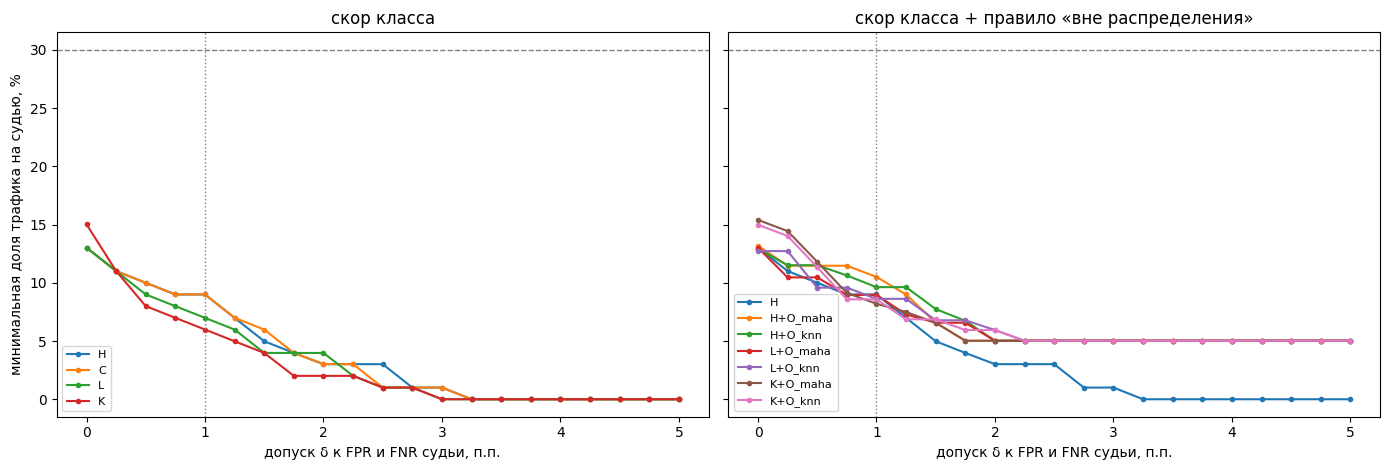

In [84]:
deltas = np.arange(0, 0.0501, 0.0025)
panels = [
    ("скор класса", list(CASCADE_SCORES)),
    ("скор класса + правило «вне распределения»", ["H"] + [v for v in VARIANTS if "+O_" in v]),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (title, names) in zip(axes, panels):
    for name in names:
        curve = min_share_curve(GRIDS[name], FPR_J_SEL, FNR_J_SEL, deltas)
        ax.plot(deltas * 100, curve * 100, marker=".", label=name)
    ax.axhline(MAX_JUDGE_SHARE * 100, color="grey", ls="--", lw=1)
    ax.axvline(DELTA_FPR * 100, color="grey", ls=":", lw=1)
    ax.set_xlabel("допуск δ к FPR и FNR судьи, п.п.")
    ax.set_title(title)
    ax.legend(fontsize=8)
axes[0].set_ylabel("минимальная доля трафика на судью, %")
plt.tight_layout()
plt.show()

## 10. Hold-out (WildGuardTest)

Отсечки с val, без изменений. Δ — разница с судьёй в п.п. на тех же бутстрэп-выборках (парный бутстрэп): если интервал Δ включает 0, каскад статистически не отличим от судьи. Время — среднее и p95 по запросам; ускорение = среднее время «всё судье» / среднее время каскада. Во второй таблице ускорение без CPU-части (токенизация и шаблон судьи), потому что CPU в Colab общий и шумный.

In [85]:
VARIANT_PARTS = {
    "p_head": [], "cos_harm": ["centroid"], "neg_maha_harm": ["maha"], "p_lda": ["lda"], "p_knn": ["knn"],
    "ood_maha": ["maha"], "ood_rmd": ["maha"], "ood_knn": ["knn"],
}


def apply_variant(name, split, ops=None, st=None):
    st = _st(st)
    ops = st["OPS"] if ops is None else ops
    score, ood = VARIANTS[name]
    judge_pred = JUDGE[split]["pred"]
    if score is None:
        return judge_pred.copy(), np.ones(len(judge_pred), dtype=bool)
    scores = st["SCORES"][split]
    flag = scores[ood] > st["OOD_TAU"][ood] if ood else None
    op = ops[name]
    return system_pred(scores[score], judge_pred, float(op["t_low"]), float(op["t_high"]), flag)


def latency_per_text(name, split, gray, gpu_only=False, st=None):
    score, ood = VARIANTS[name]
    j = JUDGE[split]
    t_judge = j["t_gpu"] if gpu_only else j["t_gpu"] + j["t_cpu"]
    if score is None:
        return t_judge
    parts = {"fwd"} if gpu_only else {"tok", "fwd"}
    parts |= set(VARIANT_PARTS[score]) | set(VARIANT_PARTS.get(ood, []))
    return sum(_st(st)["ENC_TIME"][split][p] for p in parts) + gray * t_judge


def _ci(x):
    return np.percentile(x, [2.5, 97.5])


def _pct(x, ci):
    return f"{x * 100:.1f}% [{ci[0] * 100:.1f}; {ci[1] * 100:.1f}]"


def _pp(x, ci):
    return f"{x * 100:+.1f} [{ci[0] * 100:+.1f}; {ci[1] * 100:+.1f}]"


def _times(x, ci):
    return f"{x:.2f}× [{ci[0]:.2f}; {ci[1]:.2f}]"


def evaluate_split(split, names, ops=None, n_boot=N_BOOT, gpu_only=False, routed=None, st=None):
    # Точечные значения + парный бутстрэп: одни и те же выборки для судьи и для каждого варианта.
    # routed: готовые (pred, gray) по вариантам, например из кросс-валидации; остальные — по ops.
    y = DATA[split]["label"].values
    n = len(y)
    idx = np.random.default_rng(SEED).integers(0, n, size=(n_boot, n))
    neg_b, pos_b = (y[idx] == 0), (y[idx] == 1)
    timed = split in _st(st)["ENC_TIME"]

    def run(name):
        if routed is not None and name in routed:
            pred, gray = routed[name]
        else:
            pred, gray = apply_variant(name, split, ops, st=st)
        lat = latency_per_text(name, split, gray, gpu_only, st=st) if timed else np.full(n, np.nan)
        pb = pred[idx]
        boot = {
            "share": gray[idx].mean(1),
            "fpr": (pb * neg_b).sum(1) / neg_b.sum(1),
            "fnr": ((1 - pb) * pos_b).sum(1) / pos_b.sum(1),
            "lat": lat[idx].mean(1),
        }
        return pred, gray, lat, boot

    _, _, lat_j, boot_j = run("J")
    fpr_j, fnr_j = error_rates(y, JUDGE[split]["pred"])
    num_rows, fmt_rows = [], []
    for name in names:
        pred, gray, lat, b = run(name)
        fpr, fnr = error_rates(y, pred)
        speedup = lat_j.mean() / lat.mean() if timed else np.nan
        num_rows.append({
            "вариант": name, "share": gray.mean(), "fpr": fpr, "fnr": fnr,
            "d_fpr": fpr - fpr_j, "d_fnr": fnr - fnr_j,
            "lat_mean_ms": lat.mean() * 1e3 if timed else np.nan,
            "lat_p95_ms": np.percentile(lat, 95) * 1e3 if timed else np.nan,
            "speedup": speedup,
        })
        fmt_rows.append({
            "вариант": name,
            "доля на судью": _pct(gray.mean(), _ci(b["share"])),
            "FPR": _pct(fpr, _ci(b["fpr"])),
            "FNR": _pct(fnr, _ci(b["fnr"])),
            "ΔFPR, п.п.": _pp(fpr - fpr_j, _ci(b["fpr"] - boot_j["fpr"])),
            "ΔFNR, п.п.": _pp(fnr - fnr_j, _ci(b["fnr"] - boot_j["fnr"])),
            "время, мс: ср. / p95": f"{lat.mean() * 1e3:.1f} / {np.percentile(lat, 95) * 1e3:.1f}" if timed else "—",
            "ускорение": _times(speedup, _ci(boot_j["lat"] / b["lat"])) if timed else "—",
        })
    return pd.DataFrame(num_rows).set_index("вариант"), pd.DataFrame(fmt_rows).set_index("вариант")


def cv_routing(split, names, n_folds=CV_FOLDS, st=None):
    # Отсечки подбираются тем же критерием на n_folds − 1 частях набора (с FPR/FNR судьи на них же)
    # и применяются к оставшейся части; τ_ood — по-прежнему бюджет на val_sel
    st = _st(st)
    y, judge_pred = DATA[split]["label"].values, JUDGE[split]["pred"]
    folds = stratified_folds(y, n_folds, SEED)
    routed, chosen = {}, []
    for name in names:
        score, ood = VARIANTS[name]
        if score is None:
            continue
        s = st["SCORES"][split][score]
        flag = st["SCORES"][split][ood] > st["OOD_TAU"][ood] if ood else None
        pred, gray = np.zeros(len(y), dtype=int), np.zeros(len(y), dtype=bool)
        for f in range(n_folds):
            fit, out = folds != f, folds == f
            fpr_j, fnr_j = error_rates(y[fit], judge_pred[fit])
            grid = threshold_grid(s[fit], y[fit], judge_pred[fit], None if flag is None else flag[fit])
            op = pick_operating_point(grid, fpr_j, fnr_j)
            pred[out], gray[out] = system_pred(s[out], judge_pred[out], float(op["t_low"]), float(op["t_high"]),
                                               None if flag is None else flag[out])
            chosen.append({"вариант": name, "фолд": f, "t_low": float(op["t_low"]), "t_high": float(op["t_high"]),
                           "доля на судью при подборе": float(op["share"]), "в потолке": bool(op["within_cap"])})
        routed[name] = (pred, gray)
    return routed, pd.DataFrame(chosen)


def zone_shares(name, split, st=None):
    # Куда попадает трафик: решает энкодер (safe / harm) или судья (серая зона / «вне распределения»)
    st = _st(st)
    score, ood = VARIANTS[name]
    op = st["OPS"][name]
    s = st["SCORES"][split][score]
    flag = st["SCORES"][split][ood] > st["OOD_TAU"][ood] if ood else np.zeros(len(s), dtype=bool)
    core = (s > op["t_low"]) & (s < op["t_high"])
    auto_harm = (s >= op["t_high"]) & ~flag
    return {
        "энкодер: safe": (~core & ~flag & ~auto_harm).mean(),
        "энкодер: harm": auto_harm.mean(),
        "судья: серая зона": core.mean(),
        "судья: вне распределения": (flag & ~core).mean(),
    }

In [86]:
NAMES = list(VARIANTS)
holdout_num, holdout_fmt = evaluate_split("holdout", NAMES)
display(holdout_fmt)

holdout_gpu_num, _ = evaluate_split("holdout", NAMES, gpu_only=True)
pd.DataFrame({
    "ускорение: полный запрос": holdout_num["speedup"],
    "ускорение: только GPU": holdout_gpu_num["speedup"],
}).round(2)

,доля на судью,FPR,FNR,"ΔFPR, п.п.","ΔFNR, п.п.","время, мс: ср. / p95",ускорение
вариант,,,,,,,
J,100.0% [100.0; 100.0],7.4% [5.8; 9.2],12.6% [10.4; 15.1],+0.0 [+0.0; +0.0],+0.0 [+0.0; +0.0],40.0 / 41.4,1.00× [1.00; 1.00]
H,8.9% [7.6; 10.4],7.6% [5.9; 9.4],18.3% [15.6; 21.1],+0.2 [-1.1; +1.6],+5.7 [+3.8; +7.7],12.5 / 49.0,3.20× [3.06; 3.35]
C,9.2% [7.8; 10.7],7.6% [5.9; 9.4],18.4% [15.7; 21.4],+0.2 [-1.1; +1.6],+5.8 [+3.8; +7.8],12.7 / 49.2,3.16× [3.02; 3.31]
L,7.0% [5.8; 8.2],7.8% [6.1; 9.6],18.8% [16.1; 21.7],+0.4 [-1.0; +1.8],+6.2 [+4.2; +8.4],11.8 / 48.5,3.39× [3.26; 3.54]
K,5.5% [4.5; 6.6],7.7% [6.0; 9.5],19.5% [16.8; 22.5],+0.3 [-1.1; +1.7],+6.9 [+4.9; +9.1],11.6 / 48.4,3.45× [3.32; 3.58]
H+O_maha,9.7% [8.3; 11.2],7.8% [6.1; 9.6],17.9% [15.3; 20.8],+0.4 [-0.9; +1.8],+5.3 [+3.3; +7.3],13.0 / 49.6,3.07× [2.93; 3.21]
H+O_knn,9.6% [8.2; 11.1],7.8% [6.1; 9.7],17.9% [15.3; 20.7],+0.4 [-1.0; +1.8],+5.3 [+3.3; +7.3],13.3 / 49.8,3.02× [2.89; 3.15]
L+O_maha,8.9% [7.5; 10.2],7.8% [6.1; 9.6],18.8% [16.2; 21.8],+0.4 [-0.9; +1.8],+6.2 [+4.2; +8.3],12.8 / 49.5,3.13× [3.00; 3.27]
L+O_knn,8.2% [6.9; 9.5],8.0% [6.3; 9.9],19.0% [16.2; 21.8],+0.6 [-0.9; +2.1],+6.4 [+4.3; +8.5],12.8 / 49.7,3.13× [3.00; 3.26]


,ускорение: полный запрос,ускорение: только GPU
вариант,,
J,1.00,1.00
H,3.20,3.30
C,3.16,3.26
L,3.39,3.51
K,3.45,3.56
H+O_maha,3.07,3.16
H+O_knn,3.02,3.10
L+O_maha,3.13,3.22
L+O_knn,3.13,3.22


### Справка: отсечки, подобранные на самом WildGuardTest

val — то же распределение и та же LLM-разметка, что у обучения энкодера, а WildGuardTest размечали люди. Чтобы понять, какие отсечки нужны при такой разметке, они подбираются кросс-валидацией на WildGuardTest (`CV_FOLDS` = 5 фолдов со стратификацией по метке): тот же критерий на четырёх фолдах с FPR/FNR судьи на них же, применение к пятому. Каждый текст оценивается отсечками, подобранными без него, так что это не подглядывание, но и не перенос: это ответ на вопрос «что было бы, если бы калибровочные данные были размечены так же, как тест».

Первая таблица — метрики по всем пяти отложенным фолдам вместе. Вторая — отсечки с val_sel против медианы отсечек по фолдам и сколько фолдов уложились в потолок 30%.

In [87]:
cv_routed, cv_chosen = cv_routing("holdout", NAMES)
holdout_cv_num, holdout_cv_fmt = evaluate_split("holdout", NAMES, routed=cv_routed)
display(holdout_cv_fmt)

cv_summary = cv_chosen.groupby("вариант").agg(
    t_low_cv=("t_low", "median"), t_high_cv=("t_high", "median"), folds_within_cap=("в потолке", "mean"),
)
pd.DataFrame({
    "t_low: val_sel": {n: OPS[n]["t_low"] for n in OPS},
    "t_low: CV (медиана)": cv_summary["t_low_cv"],
    "t_high: val_sel": {n: OPS[n]["t_high"] for n in OPS},
    "t_high: CV (медиана)": cv_summary["t_high_cv"],
    "доля фолдов в потолке 30%": cv_summary["folds_within_cap"],
    "доля на судью: отсечки val_sel": holdout_num["share"],
    "доля на судью: CV": holdout_cv_num["share"],
    "FNR: отсечки val_sel": holdout_num["fnr"],
    "FNR: CV": holdout_cv_num["fnr"],
}).reindex(NAMES).round(4)

,доля на судью,FPR,FNR,"ΔFPR, п.п.","ΔFNR, п.п.","время, мс: ср. / p95",ускорение
вариант,,,,,,,
J,100.0% [100.0; 100.0],7.4% [5.8; 9.2],12.6% [10.4; 15.1],+0.0 [+0.0; +0.0],+0.0 [+0.0; +0.0],40.0 / 41.4,1.00× [1.00; 1.00]
H,24.6% [22.5; 26.8],8.7% [6.7; 10.6],13.7% [11.5; 16.3],+1.3 [+0.3; +2.2],+1.1 [-0.3; +2.4],18.8 / 50.5,2.13× [2.03; 2.23]
C,24.4% [22.3; 26.4],8.5% [6.6; 10.3],13.8% [11.5; 16.4],+1.1 [+0.1; +2.0],+1.2 [-0.1; +2.5],18.8 / 50.6,2.13× [2.04; 2.23]
L,25.5% [23.4; 27.6],8.6% [6.8; 10.4],13.8% [11.6; 16.4],+1.2 [+0.3; +2.1],+1.2 [-0.1; +2.6],19.3 / 50.6,2.08× [1.99; 2.18]
K,34.2% [32.0; 36.5],8.1% [6.3; 10.0],13.8% [11.5; 16.4],+0.7 [-0.1; +1.7],+1.2 [-0.1; +2.7],23.2 / 51.1,1.73× [1.66; 1.80]
H+O_maha,25.2% [23.1; 27.4],8.8% [6.9; 10.7],13.8% [11.6; 16.3],+1.4 [+0.4; +2.3],+1.2 [-0.1; +2.5],19.3 / 50.8,2.08× [1.99; 2.17]
H+O_knn,25.5% [23.5; 27.8],8.6% [6.7; 10.4],13.7% [11.5; 16.3],+1.2 [+0.3; +2.1],+1.1 [-0.1; +2.4],19.7 / 51.0,2.03× [1.95; 2.13]
L+O_maha,26.1% [24.1; 28.3],8.7% [6.9; 10.6],13.8% [11.6; 16.3],+1.3 [+0.4; +2.2],+1.2 [-0.1; +2.6],19.7 / 50.8,2.03× [1.95; 2.12]
L+O_knn,26.4% [24.3; 28.5],8.6% [6.7; 10.5],13.8% [11.6; 16.4],+1.2 [+0.3; +2.0],+1.2 [+0.0; +2.6],20.1 / 51.1,1.99× [1.91; 2.08]


,t_low: val_sel,t_low: CV (медиана),t_high: val_sel,t_high: CV (медиана),доля фолдов в потолке 30%,доля на судью: отсечки val_sel,доля на судью: CV,FNR: отсечки val_sel,FNR: CV
J,NaN,NaN,NaN,NaN,NaN,1.0000,1.0000,0.1260,0.1260
H,0.1009,0.0344,0.4732,0.6348,1.0,0.0895,0.2460,0.1830,0.1366
C,0.8331,0.7698,0.9235,0.9457,1.0,0.0918,0.2437,0.1844,0.1379
L,0.1796,0.0425,0.5842,0.8523,1.0,0.0700,0.2554,0.1883,0.1379
K,0.1599,0.0415,0.4958,0.7585,0.0,0.0547,0.3420,0.1950,0.1379
H+O_maha,0.1009,0.0335,0.3435,0.5657,1.0,0.0965,0.2519,0.1790,0.1379
H+O_knn,0.1009,0.0344,0.2450,0.6348,1.0,0.0959,0.2554,0.1790,0.1366
L+O_maha,0.1796,0.0425,0.4532,0.8064,0.8,0.0889,0.2613,0.1883,0.1379
L+O_knn,0.1796,0.0425,0.3733,0.8523,1.0,0.0824,0.2637,0.1897,0.1379
K+O_maha,0.1599,0.0393,0.3538,0.7520,0.0,0.0765,0.3496,0.1923,0.1379


## 11. ToxicChat: перенос без перекалибровки

Те же отсечки с val_sel WildGuardMix. Ожидаемо серая зона «уедет»: доля трафика на судью и FPR/FNR изменятся. Насколько — это и есть степень обобщения: на чужом распределении схема требует перекалибровки.

In [88]:
tc_num, tc_fmt = evaluate_split("tc_test", NAMES)
display(tc_fmt)

tc_gpu_num, _ = evaluate_split("tc_test", NAMES, gpu_only=True)
pd.DataFrame({
    "ускорение: полный запрос": tc_num["speedup"],
    "ускорение: только GPU": tc_gpu_num["speedup"],
}).round(2)

,доля на судью,FPR,FNR,"ΔFPR, п.п.","ΔFNR, п.п.","время, мс: ср. / p95",ускорение
вариант,,,,,,,
J,100.0% [100.0; 100.0],6.7% [5.7; 7.7],5.8% [3.5; 8.2],+0.0 [+0.0; +0.0],+0.0 [+0.0; +0.0],39.9 / 41.1,1.00× [1.00; 1.00]
H,16.8% [15.4; 18.2],13.1% [11.7; 14.4],8.0% [5.3; 11.1],+6.4 [+5.3; +7.5],+2.2 [-0.3; +5.0],15.1 / 48.5,2.64× [2.55; 2.74]
C,16.8% [15.4; 18.2],12.7% [11.4; 14.0],7.5% [4.9; 10.4],+6.1 [+4.9; +7.1],+1.7 [-0.8; +4.3],15.1 / 48.5,2.63× [2.54; 2.73]
L,14.3% [13.1; 15.6],14.1% [12.7; 15.5],7.2% [4.7; 9.9],+7.5 [+6.3; +8.6],+1.4 [-1.1; +4.0],14.2 / 48.4,2.81× [2.71; 2.91]
K,14.2% [12.9; 15.4],14.6% [13.1; 15.9],6.9% [4.4; 9.6],+7.9 [+6.7; +9.1],+1.1 [-1.2; +3.7],14.5 / 49.0,2.74× [2.65; 2.84]
H+O_maha,25.3% [23.6; 26.8],11.0% [9.7; 12.2],8.0% [5.4; 11.0],+4.3 [+3.3; +5.3],+2.2 [+0.0; +4.8],18.7 / 49.2,2.13× [2.06; 2.20]
H+O_knn,20.2% [18.7; 21.7],10.4% [9.2; 11.7],8.6% [6.0; 11.7],+3.8 [+2.8; +4.7],+2.8 [+0.5; +5.4],16.9 / 49.2,2.35× [2.27; 2.44]
L+O_maha,24.2% [22.6; 25.6],11.5% [10.1; 12.7],7.5% [4.9; 10.3],+4.8 [+3.7; +5.9],+1.7 [-0.6; +4.0],18.4 / 49.3,2.17× [2.11; 2.25]
L+O_knn,18.6% [17.2; 20.0],10.9% [9.6; 12.1],7.7% [5.1; 10.7],+4.3 [+3.2; +5.2],+1.9 [-0.3; +4.5],16.4 / 49.1,2.43× [2.35; 2.52]


,ускорение: полный запрос,ускорение: только GPU
вариант,,
J,1.00,1.00
H,2.64,2.67
C,2.63,2.66
L,2.81,2.84
K,2.74,2.76
H+O_maha,2.13,2.15
H+O_knn,2.35,2.37
L+O_maha,2.17,2.19
L+O_knn,2.43,2.45


### Куда сдвинулся трафик

Распределение скора на val_sel (WildGuardMix) и на ToxicChat test, пунктир — отсечки с val_sel. Ниже — доли трафика по зонам для основных вариантов на трёх наборах.

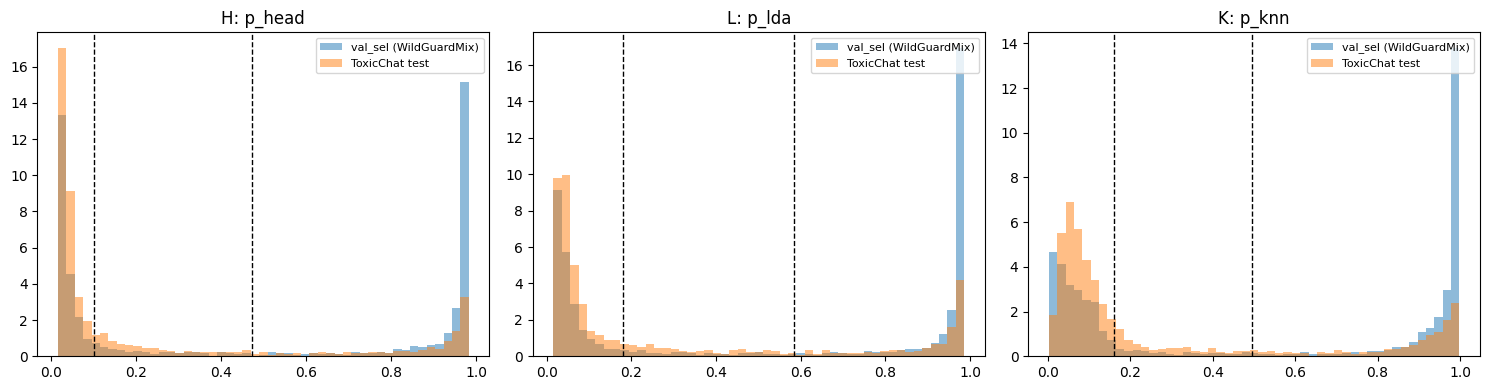

энкодер: safe  энкодер: harm  судья: серая зона  \
вариант  набор                                                      
H        val_sel           42.0           49.0                9.0   
         holdout           55.3           35.8                8.9   
         tc_test           62.8           20.4               16.8   
L        val_sel           43.0           50.0                7.0   
         holdout           56.3           36.7                7.0   
         tc_test           63.8           21.9               14.3   
K        val_sel           44.0           50.0                6.0   
         holdout           57.5           37.0                5.5   
         tc_test           63.6           22.3               14.2   
H+O_maha val_sel           41.8           47.7                7.0   
         holdout           55.1           35.3                7.2   
         tc_test           57.9           16.8               13.5   
H+O_knn  val_sel           42.0           48.4                5.0   
         holdout           55.3           35.1                5.7   
         tc_test           62.8           17.0               10.8   
K+O_knn  val_sel           42.8           48.6                4.0   
         holdout           56.5           35.4                4.0   
         tc_test           61.1           18.5               10.1   

                  судья: вне распределения  
вариант  набор                              
H        val_sel                       0.0  
         holdout                       0.0  
         tc_test                       0.0  
L        val_sel                       0.0  
         holdout                       0.0  
         tc_test                       0.0  
K        val_sel                       0.0  
         holdout                       0.0  
         tc_test                       0.0  
H+O_maha val_sel                       3.5  
         holdout                       2.4  
         tc_test                      11.7  
H+O_knn  val_sel                       4.6  
         holdout                       3.9  
         tc_test                       9.4  
K+O_knn  val_sel                       4.6  
         holdout                       4.1  
         tc_test                      10.3

In [89]:
MAIN_VARIANTS = ["H", "L", "K", "H+O_maha", "H+O_knn", "K+O_knn"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["H", "L", "K"]):
    score = VARIANTS[name][0]
    values = np.r_[SCORES["val_sel"][score], SCORES["tc_test"][score]]
    bins = np.linspace(values.min(), values.max(), 50)
    for split, label in [("val_sel", "val_sel (WildGuardMix)"), ("tc_test", "ToxicChat test")]:
        ax.hist(SCORES[split][score], bins=bins, density=True, alpha=0.5, label=label)
    for t in (OPS[name]["t_low"], OPS[name]["t_high"]):
        if np.isfinite(t):
            ax.axvline(t, color="k", ls="--", lw=1)
    ax.set_title(f"{name}: {score}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

zones = pd.DataFrame({(name, split): zone_shares(name, split)
                      for name in MAIN_VARIANTS for split in EVAL_SETS}).T
zones.index.names = ["вариант", "набор"]
(zones * 100).round(1)

### Справка: перекалибровка на ToxicChat train

Тот же критерий, но отсечки подобраны на ToxicChat train (с судьёй на нём же) и применены к ToxicChat test. Разница с таблицей выше — цена того, что отсечки подбирались на чужом распределении. τ_ood остаётся с val_sel: это бюджет на трафике того же распределения, что и обучение.

In [90]:
def retune_on_tc_train(st=None):
    # Отсечки тем же критерием на ToxicChat train с FPR/FNR судьи на нём же; τ_ood остаётся с val_sel
    st = _st(st)
    y_tr, jp_tr = DATA["tc_train"]["label"].values, JUDGE["tc_train"]["pred"]
    fpr_j_tr, fnr_j_tr = error_rates(y_tr, jp_tr)
    ops = {}
    for name, (score, ood) in VARIANTS.items():
        if score is None:
            continue
        scores = st["SCORES"]["tc_train"]
        flag = scores[ood] > st["OOD_TAU"][ood] if ood else None
        ops[name] = pick_operating_point(threshold_grid(scores[score], y_tr, jp_tr, flag), fpr_j_tr, fnr_j_tr)
    return ops


if "tc_train" in JUDGE:
    print("Судья на ToxicChat train: FPR = {:.2%}, FNR = {:.2%}".format(
        *error_rates(DATA["tc_train"]["label"].values, JUDGE["tc_train"]["pred"])))
    OPS_TC = retune_on_tc_train()
    tc_retuned_num, tc_retuned_fmt = evaluate_split("tc_test", NAMES, ops=OPS_TC)
    display(pd.DataFrame({
        "t_low: val_sel": {n: OPS[n]["t_low"] for n in OPS},
        "t_low: ToxicChat train": {n: OPS_TC[n]["t_low"] for n in OPS_TC},
        "t_high: val_sel": {n: OPS[n]["t_high"] for n in OPS},
        "t_high: ToxicChat train": {n: OPS_TC[n]["t_high"] for n in OPS_TC},
        "в потолке 30% (ToxicChat train)": {n: OPS_TC[n]["within_cap"] for n in OPS_TC},
        "доля на судью: отсечки val_sel": tc_num["share"],
        "доля на судью: отсечки ToxicChat": tc_retuned_num["share"],
        "FPR: отсечки val_sel": tc_num["fpr"],
        "FPR: отсечки ToxicChat": tc_retuned_num["fpr"],
        "FNR: отсечки val_sel": tc_num["fnr"],
        "FNR: отсечки ToxicChat": tc_retuned_num["fnr"],
    }).reindex(NAMES).round(4))
    display(tc_retuned_fmt)
else:
    print("RUN_TOXICCHAT_TRAIN = False: перекалибровка пропущена")

Судья на ToxicChat train: FPR = 5.01%, FNR = 6.77%


,t_low: val_sel,t_low: ToxicChat train,t_high: val_sel,t_high: ToxicChat train,в потолке 30% (ToxicChat train),доля на судью: отсечки val_sel,доля на судью: отсечки ToxicChat,FPR: отсечки val_sel,FPR: отсечки ToxicChat,FNR: отсечки val_sel,FNR: отсечки ToxicChat
J,NaN,NaN,NaN,NaN,NaN,1.0000,1.0000,0.0666,0.0666,0.0580,0.0580
H,0.1009,0.0987,0.4732,0.9247,True,0.1679,0.2685,0.1309,0.0703,0.0801,0.0912
C,0.8331,0.8391,0.9235,0.9799,True,0.1675,0.2520,0.1273,0.0690,0.0746,0.0939
L,0.1796,0.1798,0.5842,0.9541,True,0.1430,0.2566,0.1413,0.0703,0.0718,0.0856
K,0.1599,0.1573,0.4958,0.9509,True,0.1416,0.2818,0.1457,0.0711,0.0691,0.0884
H+O_maha,0.1009,0.1170,0.3435,0.9247,False,0.2527,0.3067,0.1096,0.0690,0.0801,0.0939
H+O_knn,0.1009,0.0987,0.2450,0.9247,True,0.2019,0.2685,0.1044,0.0703,0.0856,0.0912
L+O_maha,0.1796,0.1943,0.4532,0.9541,False,0.2419,0.3049,0.1148,0.0707,0.0746,0.0884
L+O_knn,0.1796,0.1798,0.3733,0.9541,True,0.1861,0.2569,0.1092,0.0707,0.0773,0.0856
K+O_maha,0.1599,0.1633,0.3538,0.9444,False,0.2464,0.3176,0.1160,0.0743,0.0691,0.0884


,доля на судью,FPR,FNR,"ΔFPR, п.п.","ΔFNR, п.п.","время, мс: ср. / p95",ускорение
вариант,,,,,,,
J,100.0% [100.0; 100.0],6.7% [5.7; 7.7],5.8% [3.5; 8.2],+0.0 [+0.0; +0.0],+0.0 [+0.0; +0.0],39.9 / 41.1,1.00× [1.00; 1.00]
H,26.8% [25.1; 28.4],7.0% [6.0; 8.1],9.1% [6.4; 12.2],+0.4 [-0.3; +1.0],+3.3 [+1.2; +5.9],19.1 / 48.9,2.09× [2.02; 2.16]
C,25.2% [23.5; 26.7],6.9% [5.8; 8.0],9.4% [6.6; 12.5],+0.2 [-0.4; +0.9],+3.6 [+1.4; +6.2],18.5 / 48.9,2.15× [2.08; 2.24]
L,25.7% [24.0; 27.2],7.0% [6.0; 8.0],8.6% [5.9; 11.6],+0.4 [-0.3; +1.0],+2.8 [+0.6; +5.1],18.7 / 49.0,2.13× [2.06; 2.21]
K,28.2% [26.5; 29.7],7.1% [6.1; 8.2],8.8% [6.0; 11.8],+0.4 [-0.2; +1.1],+3.0 [+1.1; +5.2],20.2 / 49.8,1.98× [1.92; 2.05]
H+O_maha,30.7% [28.9; 32.2],6.9% [5.9; 7.9],9.4% [6.7; 12.5],+0.2 [-0.4; +0.9],+3.6 [+1.4; +6.0],20.9 / 49.4,1.91× [1.86; 1.98]
H+O_knn,26.8% [25.1; 28.4],7.0% [6.0; 8.1],9.1% [6.4; 12.2],+0.4 [-0.3; +1.0],+3.3 [+1.2; +5.9],19.6 / 49.4,2.03× [1.97; 2.11]
L+O_maha,30.5% [28.7; 31.9],7.1% [6.0; 8.1],8.8% [6.1; 11.9],+0.4 [-0.2; +1.1],+3.0 [+0.8; +5.3],20.9 / 49.5,1.91× [1.86; 1.98]
L+O_knn,25.7% [24.0; 27.2],7.1% [6.1; 8.1],8.6% [5.9; 11.6],+0.4 [-0.3; +1.1],+2.8 [+0.6; +5.1],19.2 / 49.5,2.07× [2.01; 2.15]


## 12. Срезы

- hold-out: vanilla / adversarial и промты длиннее 512 токенов (энкодер видит их не целиком, судья — целиком);
- ToxicChat по категориям метки. Пустые срезы не показываются: в `toxicchat0124` test нет промтов только с `jailbreaking` — все они ещё и toxicity, поэтому метка `any` там совпадает с `toxicity` (ячейка это проверяет).

FPR считается только на safe-промтах среза, FNR — только на harm, поэтому в срезах из одного класса второе значение пустое. Значения в процентах.

In [91]:
SLICE_VARIANTS = ["J"] + MAIN_VARIANTS


def slice_tables(split, masks, y=None, names=SLICE_VARIANTS):
    y = DATA[split]["label"].values if y is None else np.asarray(y)
    masks = {k: np.asarray(m, dtype=bool) for k, m in masks.items() if np.asarray(m, dtype=bool).any()}
    rows = []
    for name in names:
        pred, gray = apply_variant(name, split)
        for slice_name, mask in masks.items():
            fpr, fnr = error_rates(y[mask], pred[mask])
            rows.append({"срез": f"{slice_name} (n={mask.sum()})", "вариант": name,
                         "доля на судью": gray[mask].mean(), "FPR": fpr, "FNR": fnr})
    long = pd.DataFrame(rows)
    order = list(dict.fromkeys(long["срез"]))
    for metric in ("доля на судью", "FPR", "FNR"):
        print(metric)
        display((long.pivot(index="срез", columns="вариант", values=metric).loc[order, names] * 100).round(1))


h = DATA["holdout"]
print("=== hold-out ===")
slice_tables("holdout", {
    "все": np.ones(len(h), dtype=bool),
    "vanilla": ~h["adversarial"].values.astype(bool),
    "adversarial": h["adversarial"].values.astype(bool),
    "≤ 512 токенов": ~h["truncated"].values,
    "> 512 токенов": h["truncated"].values,
})

tc = DATA["tc_test"]
cat = tc["category"].values
n_label_diff = int((tc["label"].values != tc["label_toxicity"].values).sum())
print("=== ToxicChat test ===")
print("Метка any совпадает с toxicity на всех промтах" if n_label_diff == 0
      else f"Метки any и toxicity расходятся на {n_label_diff} промтах (только jailbreaking)")
slice_tables("tc_test", {
    "все": np.ones(len(tc), dtype=bool),
    **{c: cat == c for c in ("safe", "toxicity", "jailbreaking", "toxicity+jailbreaking")},
    "> 512 токенов": tc["truncated"].values,
})

=== hold-out ===
доля на судью


вариант,J,H,L,K,H+O_maha,H+O_knn,K+O_knn
срез,,,,,,,
все (n=1699),100.0,8.9,7.0,5.5,9.7,9.6,8.1
vanilla (n=903),100.0,4.8,3.5,2.0,4.4,4.4,2.5
adversarial (n=796),100.0,13.7,10.9,9.4,15.6,15.5,14.3
≤ 512 токенов (n=1696),100.0,9.0,7.0,5.5,9.7,9.6,8.1
> 512 токенов (n=3),100.0,0.0,0.0,0.0,0.0,0.0,0.0


FPR


вариант,J,H,L,K,H+O_maha,H+O_knn,K+O_knn
срез,,,,,,,
все (n=1699),7.4,7.6,7.8,7.7,7.8,7.8,8.0
vanilla (n=903),2.9,2.4,2.7,2.4,2.9,2.7,2.4
adversarial (n=796),12.3,13.2,13.4,13.4,13.2,13.4,14.1
≤ 512 токенов (n=1696),7.4,7.6,7.8,7.7,7.8,7.8,8.1
> 512 токенов (n=3),0.0,0.0,0.0,0.0,0.0,0.0,0.0


FNR


...

вариант,J,H,L,K,H+O_maha,H+O_knn,K+O_knn
срез,,,,,,,
все (n=2853),100.0,16.8,14.3,14.2,25.3,20.2,20.4
safe (n=2491),100.0,17.7,15.1,14.9,26.4,21.0,21.5
toxicity (n=271),100.0,9.6,8.9,8.1,15.9,12.9,12.5
toxicity+jailbreaking (n=91),100.0,13.2,9.9,11.0,22.0,18.7,14.3
> 512 токенов (n=10),100.0,0.0,0.0,10.0,30.0,0.0,10.0


FPR


вариант,J,H,L,K,H+O_maha,H+O_knn,K+O_knn
срез,,,,,,,
все (n=2853),6.7,13.1,14.1,14.6,11.0,10.4,11.6
safe (n=2491),6.7,13.1,14.1,14.6,11.0,10.4,11.6
toxicity (n=271),NaN,NaN,NaN,NaN,NaN,NaN,NaN
toxicity+jailbreaking (n=91),NaN,NaN,NaN,NaN,NaN,NaN,NaN
> 512 токенов (n=10),10.0,0.0,0.0,0.0,0.0,0.0,0.0


FNR


вариант,J,H,L,K,H+O_maha,H+O_knn,K+O_knn
срез,,,,,,,
все (n=2853),5.8,8.0,7.2,6.9,8.0,8.6,7.5
safe (n=2491),NaN,NaN,NaN,NaN,NaN,NaN,NaN
toxicity (n=271),5.5,7.7,6.6,6.3,7.4,8.1,7.0
toxicity+jailbreaking (n=91),6.6,8.8,8.8,8.8,9.9,9.9,8.8
> 512 токенов (n=10),NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 13. Пропускная способность (дополнительно)

Режим batch = 1 выше — то, что видит пользователь. Здесь офлайн-режим на hold-out: энкодер батчами со всеми скорами сразу на всех текстах (верхняя оценка для любого варианта) плюс судья батчами только на ушедших к нему текстах — это реальный прогон, а не оценка. Внутри батча тексты сгруппированы по длине, и от этого результат зависит, поэтому числа справочные.

In [92]:
@torch.inference_mode()
def encoder_batch_seconds(texts, batch_size=64):
    _sync()
    t0 = time.perf_counter()
    raw = encode_raw(texts, batch_size=batch_size)
    head_proba(raw)
    geometry_scores(G, raw)
    knn_scores(KNN_INDEX, raw, ks=(BEST_K,))
    _sync()
    return time.perf_counter() - t0


@torch.inference_mode()
def judge_batch_seconds(texts, batch_size=16):
    if not texts:
        return 0.0
    old_side = judge_tok.padding_side
    judge_tok.padding_side = "left"   # последняя позиция должна быть последним токеном промта
    order = np.argsort([len(t) for t in texts], kind="stable")
    _sync()
    t0 = time.perf_counter()
    for start in range(0, len(texts), batch_size):
        chunk = [render_judge_prompt(texts[i]) for i in order[start:start + batch_size]]
        inputs = judge_tok(chunk, return_tensors="pt", padding=True).to(DEVICE)
        judge_forward(inputs).argmax(-1).cpu()
    _sync()
    judge_tok.padding_side = old_side
    return time.perf_counter() - t0


if RUN_THROUGHPUT:
    texts = DATA["holdout"]["text"].tolist()
    encoder_batch_seconds(texts[:256])   # прогрев
    judge_batch_seconds(texts[:32])
    t_encoder_all = encoder_batch_seconds(texts)
    t_judge_all = judge_batch_seconds(texts)
    rows = [{"вариант": "J", "доля на судью": 1.0, "текстов/с": len(texts) / t_judge_all, "ускорение": 1.0}]
    for name in MAIN_VARIANTS:
        _, gray = apply_variant(name, "holdout")
        total = t_encoder_all + judge_batch_seconds([texts[i] for i in np.where(gray)[0]])
        rows.append({"вариант": name, "доля на судью": gray.mean(), "текстов/с": len(texts) / total,
                     "ускорение": t_judge_all / total})
    display(pd.DataFrame(rows).set_index("вариант").round(3))

encode:   0%|          | 0/4 [00:00<?, ?it/s]

encode:   0%|          | 0/27 [00:00<?, ?it/s]

,доля на судью,текстов/с,ускорение
вариант,,,
J,1.000,49.727,1.000
H,0.089,303.397,6.101
L,0.070,349.241,7.023
K,0.055,380.630,7.654
H+O_maha,0.097,279.107,5.613
H+O_knn,0.096,281.220,5.655
K+O_knn,0.081,307.163,6.177


## 14. Сравнение: CE против SupCon + CE

Тот же каскад, тот же судья, те же данные и правила подбора отсечек, но другой энкодер: `pineee/e5-small-v2-hivetrace-finetune-CE` обучен только с CE на тех же 43 025 текстах и с тем же числом шагов. Вопрос — даёт ли SupCon при обучении выигрыш в каскаде: меньше трафика на судью при том же качестве или лучший перенос на ToxicChat.

Для CE заново считаются эмбеддинги, проверка по карточке (порог головы на val 0.9711), геометрия (своя усадка LDA и своё k), время на запрос и отсечки на val_sel. Судья общий: его ответы от энкодера не зависят. Переменные основного энкодера не меняются, состояние остальных хранится в словаре `STATES`.

Таблицы:
1. Подобранные гиперпараметры и время прямого прохода. Архитектура у энкодеров одна, так что время должно совпасть, и разница в ускорении — это разница в доле трафика на судью.
2. Разделимость скоров на WildGuardTest и ToxicChat.
3. По каждому из четырёх режимов (отсечки с val_sel и кросс-валидация на WildGuardTest; отсечки с val_sel и перекалибровка на ToxicChat) — доля на судью, ΔFPR и ΔFNR к судье и ускорение для обоих энкодеров.
4. Парный бутстрэп разности «SupCon + CE минус CE» на одних и тех же выборках. Отрицательная Δ доли на судью значит, что SupCon + CE отдаёт судье меньше; отрицательные ΔFPR и ΔFNR — что он реже ошибается.
5. Та же парная разность, но для разных вариантов: SupCon + CE с родной головой (H) против CE со скором по центру harm (C). Она проверяет, закрывает ли смена скора у CE разницу с SupCon + CE на ToxicChat: у CE голова на чужом трафике ошибается чаще, а положение относительно центров классов переносится лучше.

In [93]:
STATES = {MAIN_ENCODER: globals()}
for key, spec in ENCODERS.items():
    if key == MAIN_ENCODER:
        continue
    st = {}
    st["enc_tokenizer"], st["encoder"], st["head"] = load_encoder(spec["repo"])
    st["EMB"], st["P_HEAD"] = compute_embeddings(spec["repo"], st=st)
    st["val_threshold"], card = card_check(spec, st["P_HEAD"])
    print(f"Проверка по карточке: {key}")
    display(card.round(4))
    st.update(fit_scores(st["EMB"], st["P_HEAD"]))
    st["GEO_T"] = geo_tensors(st["G"], st["KNN_INDEX"])
    st["ENC_TIME"] = measure_encoder_time(spec["repo"], st=st)
    st["OOD_TAU"], st["GRIDS"], st["OPS"] = select_operating_points(st["SCORES"])
    STATES[key] = st

pd.DataFrame({
    key: {"LDA: α": st["BEST_ALPHA"], "kNN: k": st["BEST_K"],
          "прямой проход, мс (медиана, hold-out)": np.median(st["ENC_TIME"]["holdout"]["fwd"]) * 1e3}
    for key, st in STATES.items()
}).T

config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/391 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

энкодер, повтор 3/3:   0%|          | 0/1699 [00:00<?, ?it/s]

энкодер, повтор 1/3:   0%|          | 0/2853 [00:00<?, ?it/s]

энкодер, повтор 2/3:   0%|          | 0/2853 [00:00<?, ?it/s]

энкодер, повтор 3/3:   0%|          | 0/2853 [00:00<?, ?it/s]

,LDA: α,kNN: k,"прямой проход, мс (медиана, hold-out)"
SupCon+CE,0.7,50.0,8.133149
CE,1.0,50.0,7.864387


In [94]:
rows = []
for key, st in STATES.items():
    for short, score in CASCADE_SCORES.items():
        row = {"скор": short, "энкодер": key}
        for name in ("holdout", "tc_test"):
            y = DATA[name]["label"].values
            row[f"AUROC {name}"] = roc_auc_score(y, st["SCORES"][name][score])
            row[f"TPR@1%FPR {name}"] = tpr_at_fpr(y, st["SCORES"][name][score])[0]
        rows.append(row)
pd.DataFrame(rows).set_index(["скор", "энкодер"]).loc[list(CASCADE_SCORES)].round(3)

AUROC holdout  TPR@1%FPR holdout  AUROC tc_test  \
скор энкодер                                                      
H    SupCon+CE          0.932              0.509          0.934   
     CE                 0.925              0.398          0.925   
C    SupCon+CE          0.933              0.537          0.934   
     CE                 0.920              0.420          0.935   
L    SupCon+CE          0.930              0.556          0.930   
     CE                 0.926              0.386          0.922   
K    SupCon+CE          0.913              0.524          0.927   
     CE                 0.901              0.366          0.911   

                TPR@1%FPR tc_test  
скор энкодер                       
H    SupCon+CE              0.359  
     CE                     0.122  
C    SupCon+CE              0.240  
     CE                     0.373  
L    SupCon+CE              0.337  
     CE                     0.072  
K    SupCon+CE              0.309  
     CE                     0.036

In [ ]:
COMPARE_VARIANTS = ["J", "H", "C", "L", "K", "H+O_maha", "H+O_knn"]
REGIMES = {
    "holdout_valsel": "WildGuardTest, отсечки val_sel",
    "holdout_cv": "WildGuardTest, кросс-валидация",
    "tc_valsel": "ToxicChat, отсечки val_sel",
    "tc_retuned": "ToxicChat, перекалибровка на ToxicChat train",
}


def regime_routing(st, names=COMPARE_VARIANTS):
    # Решения (pred, gray) каждого варианта во всех режимах для одного энкодера: {режим: (набор, {вариант: ...})}
    def by_ops(split, ops=None):
        return {n: apply_variant(n, split, ops, st=st) for n in names}

    out = {
        "holdout_valsel": ("holdout", by_ops("holdout")),
        # J остаётся «всё судье», остальные варианты — из кросс-валидации
        "holdout_cv": ("holdout", {**by_ops("holdout"), **cv_routing("holdout", names, st=st)[0]}),
        "tc_valsel": ("tc_test", by_ops("tc_test")),
    }
    if "tc_train" in JUDGE:
        out["tc_retuned"] = ("tc_test", by_ops("tc_test", retune_on_tc_train(st=st)))
    return out


def paired_difference(regime, name, key_a, key_b, n_boot=N_BOOT, name_b=None):
    # Разность «a − b» для одного режима на одних и тех же бутстрэп-выборках.
    # name — вариант энкодера a; name_b — вариант энкодера b, если он другой (по умолчанию тот же).
    name_b = name if name_b is None else name_b
    split = ROUTING[key_a][regime][0]
    y = DATA[split]["label"].values
    idx = np.random.default_rng(SEED).integers(0, len(y), size=(n_boot, len(y)))
    neg_b, pos_b = y[idx] == 0, y[idx] == 1

    def metrics(key, variant):
        pred, gray = ROUTING[key][regime][1][variant]
        lat = latency_per_text(variant, split, gray, st=STATES[key])
        fpr, fnr = error_rates(y, pred)
        pb = pred[idx]
        point = {"доля на судью": gray.mean(), "FPR": fpr, "FNR": fnr, "время": lat.mean()}
        boot = {"доля на судью": gray[idx].mean(1), "FPR": (pb * neg_b).sum(1) / neg_b.sum(1),
                "FNR": ((1 - pb) * pos_b).sum(1) / pos_b.sum(1), "время": lat[idx].mean(1)}
        return point, boot

    (point_a, boot_a), (point_b, boot_b) = metrics(key_a, name), metrics(key_b, name_b)
    out = {}
    for metric, unit, scale in (("доля на судью", "п.п.", 100), ("FPR", "п.п.", 100), ("FNR", "п.п.", 100),
                                ("время", "мс", 1000)):
        lo, hi = np.percentile(boot_a[metric] - boot_b[metric], [2.5, 97.5]) * scale
        out[f"Δ {metric}, {unit}"] = f"{(point_a[metric] - point_b[metric]) * scale:+.1f} [{lo:+.1f}; {hi:+.1f}]"
    return out

In [96]:
ROUTING = {key: regime_routing(st) for key, st in STATES.items()}
COMPARE_NUM = {}
for regime, title in REGIMES.items():
    if regime not in ROUTING[MAIN_ENCODER]:
        continue
    split = ROUTING[MAIN_ENCODER][regime][0]
    tables = {}
    for key, st in STATES.items():
        num, fmt = evaluate_split(split, COMPARE_VARIANTS, routed=ROUTING[key][regime][1], st=st)
        COMPARE_NUM[(key, regime)] = num
        tables[key] = fmt[["доля на судью", "ΔFPR, п.п.", "ΔFNR, п.п.", "ускорение"]]
    print(f"=== {title} ===")
    display(pd.concat(tables, axis=1))

rows = []
for key in STATES:
    if key == MAIN_ENCODER:
        continue
    for regime, title in REGIMES.items():
        if regime not in ROUTING[MAIN_ENCODER]:
            continue
        for name in ("H", "L", "H+O_knn"):
            rows.append({"разность": f"{MAIN_ENCODER} − {key}", "режим": title, "вариант": name,
                         **paired_difference(regime, name, MAIN_ENCODER, key)})
print("=== Парная разность, 95% интервалы ===")
pd.DataFrame(rows).set_index(["разность", "режим", "вариант"])

=== WildGuardTest, отсечки val_sel ===


SupCon+CE                                        \
                  доля на судью         ΔFPR, п.п.         ΔFNR, п.п.   
вариант                                                                 
J         100.0% [100.0; 100.0]  +0.0 [+0.0; +0.0]  +0.0 [+0.0; +0.0]   
H              8.9% [7.6; 10.4]  +0.2 [-1.1; +1.6]  +5.7 [+3.8; +7.7]   
C              9.2% [7.8; 10.7]  +0.2 [-1.1; +1.6]  +5.8 [+3.8; +7.8]   
L               7.0% [5.8; 8.2]  +0.4 [-1.0; +1.8]  +6.2 [+4.2; +8.4]   
K               5.5% [4.5; 6.6]  +0.3 [-1.1; +1.7]  +6.9 [+4.9; +9.1]   
H+O_maha       9.7% [8.3; 11.2]  +0.4 [-0.9; +1.8]  +5.3 [+3.3; +7.3]   
H+O_knn        9.6% [8.2; 11.1]  +0.4 [-1.0; +1.8]  +5.3 [+3.3; +7.3]   

                                                 CE                     \
                   ускорение          доля на судью         ΔFPR, п.п.   
вариант                                                                  
J         1.00× [1.00; 1.00]  100.0% [100.0; 100.0]  +0.0 [+0.0; +0.0]   
H         3.20× [3.06; 3.35]        5.4% [4.3; 6.5]  +1.0 [-0.5; +2.5]   
C         3.16× [3.02; 3.31]        5.1% [4.0; 6.2]  +1.1 [-0.5; +2.7]   
L         3.39× [3.26; 3.54]        5.4% [4.4; 6.5]  +0.8 [-0.6; +2.4]   
K         3.45× [3.32; 3.58]        4.6% [3.6; 5.6]  +0.6 [-0.8; +2.2]   
H+O_maha  3.07× [2.93; 3.21]        7.8% [6.5; 9.1]  +0.7 [-0.5; +2.2]   
H+O_knn   3.02× [2.89; 3.15]        7.1% [5.9; 8.4]  +0.2 [-1.2; +1.7]   

                                                 
                 ΔFNR, п.п.           ускорение  
вариант                                          
J         +0.0 [+0.0; +0.0]  1.00× [1.00; 1.00]  
H         +6.5 [+4.3; +8.7]  3.73× [3.58; 3.89]  
C         +7.3 [+5.2; +9.5]  3.75× [3.60; 3.92]  
L         +6.5 [+4.3; +8.7]  3.71× [3.56; 3.86]  
K         +7.4 [+5.3; +9.7]  3.68× [3.55; 3.82]  
H+O_maha  +5.7 [+3.8; +7.9]  3.37× [3.22; 3.52]  
H+O_knn   +6.4 [+4.3; +8.6]  3.37× [3.23; 3.51]

=== WildGuardTest, кросс-валидация ===


SupCon+CE                                        \
                  доля на судью         ΔFPR, п.п.         ΔFNR, п.п.   
вариант                                                                 
J         100.0% [100.0; 100.0]  +0.0 [+0.0; +0.0]  +0.0 [+0.0; +0.0]   
H            24.6% [22.5; 26.8]  +1.3 [+0.3; +2.2]  +1.1 [-0.3; +2.4]   
C            24.4% [22.3; 26.4]  +1.1 [+0.1; +2.0]  +1.2 [-0.1; +2.5]   
L            25.5% [23.4; 27.6]  +1.2 [+0.3; +2.1]  +1.2 [-0.1; +2.6]   
K            34.2% [32.0; 36.5]  +0.7 [-0.1; +1.7]  +1.2 [-0.1; +2.7]   
H+O_maha     25.2% [23.1; 27.4]  +1.4 [+0.4; +2.3]  +1.2 [-0.1; +2.5]   
H+O_knn      25.5% [23.5; 27.8]  +1.2 [+0.3; +2.1]  +1.1 [-0.1; +2.4]   

                                                 CE                     \
                   ускорение          доля на судью         ΔFPR, п.п.   
вариант                                                                  
J         1.00× [1.00; 1.00]  100.0% [100.0; 100.0]  +0.0 [+0.0; +0.0]   
H         2.13× [2.03; 2.23]     25.1% [23.0; 27.1]  +0.7 [+0.0; +1.6]   
C         2.13× [2.04; 2.23]     28.4% [26.3; 30.7]  +1.0 [+0.1; +1.8]   
L         2.08× [1.99; 2.18]     24.5% [22.5; 26.5]  +0.8 [+0.1; +1.7]   
K         1.73× [1.66; 1.80]     45.1% [42.7; 47.6]  +0.6 [-0.1; +1.5]   
H+O_maha  2.08× [1.99; 2.17]     25.7% [23.7; 27.8]  +0.8 [+0.1; +1.7]   
H+O_knn   2.03× [1.95; 2.13]     24.8% [22.7; 26.9]  +1.0 [+0.1; +1.9]   

                                                 
                 ΔFNR, п.п.           ускорение  
вариант                                          
J         +0.0 [+0.0; +0.0]  1.00× [1.00; 1.00]  
H         +1.1 [-0.3; +2.6]  2.14× [2.05; 2.24]  
C         +0.9 [-0.3; +2.2]  2.00× [1.91; 2.09]  
L         +1.1 [-0.3; +2.4]  2.16× [2.07; 2.26]  
K         +0.9 [-0.4; +2.3]  1.47× [1.42; 1.53]  
H+O_maha  +1.1 [-0.3; +2.4]  2.09× [2.00; 2.19]  
H+O_knn   +1.2 [-0.1; +2.7]  2.10× [2.01; 2.20]

=== ToxicChat, отсечки val_sel ===


SupCon+CE                                        \
                  доля на судью         ΔFPR, п.п.         ΔFNR, п.п.   
вариант                                                                 
J         100.0% [100.0; 100.0]  +0.0 [+0.0; +0.0]  +0.0 [+0.0; +0.0]   
H            16.8% [15.4; 18.2]  +6.4 [+5.3; +7.5]  +2.2 [-0.3; +5.0]   
C            16.8% [15.4; 18.2]  +6.1 [+4.9; +7.1]  +1.7 [-0.8; +4.3]   
L            14.3% [13.1; 15.6]  +7.5 [+6.3; +8.6]  +1.4 [-1.1; +4.0]   
K            14.2% [12.9; 15.4]  +7.9 [+6.7; +9.1]  +1.1 [-1.2; +3.7]   
H+O_maha     25.3% [23.6; 26.8]  +4.3 [+3.3; +5.3]  +2.2 [+0.0; +4.8]   
H+O_knn      20.2% [18.7; 21.7]  +3.8 [+2.8; +4.7]  +2.8 [+0.5; +5.4]   

                                                 CE                      \
                   ускорение          доля на судью          ΔFPR, п.п.   
вариант                                                                   
J         1.00× [1.00; 1.00]  100.0% [100.0; 100.0]   +0.0 [+0.0; +0.0]   
H         2.64× [2.55; 2.74]       9.3% [8.2; 10.3]   +8.5 [+7.3; +9.7]   
C         2.63× [2.54; 2.73]        8.8% [7.7; 9.8]   +7.6 [+6.4; +8.8]   
L         2.81× [2.71; 2.91]       9.6% [8.5; 10.7]  +8.8 [+7.5; +10.0]   
K         2.74× [2.65; 2.84]        7.8% [6.8; 8.8]   +7.9 [+6.6; +9.1]   
H+O_maha  2.13× [2.06; 2.20]     31.9% [30.2; 33.5]   +3.8 [+2.9; +4.8]   
H+O_knn   2.35× [2.27; 2.44]     17.3% [15.8; 18.7]   +4.2 [+3.2; +5.1]   

                                                 
                 ΔFNR, п.п.           ускорение  
вариант                                          
J         +0.0 [+0.0; +0.0]  1.00× [1.00; 1.00]  
H         +2.2 [-0.3; +4.9]  3.36× [3.24; 3.48]  
C         +2.8 [+0.3; +5.6]  3.39× [3.28; 3.53]  
L         +1.9 [-0.5; +4.5]  3.30× [3.19; 3.43]  
K         +3.6 [+0.8; +6.6]  3.39× [3.28; 3.51]  
H+O_maha  +2.2 [-0.3; +4.8]  1.89× [1.83; 1.95]  
H+O_knn   +1.9 [-0.5; +4.5]  2.56× [2.48; 2.66]

=== ToxicChat, перекалибровка на ToxicChat train ===


SupCon+CE                                        \
                  доля на судью         ΔFPR, п.п.         ΔFNR, п.п.   
вариант                                                                 
J         100.0% [100.0; 100.0]  +0.0 [+0.0; +0.0]  +0.0 [+0.0; +0.0]   
H            26.8% [25.1; 28.4]  +0.4 [-0.3; +1.0]  +3.3 [+1.2; +5.9]   
C            25.2% [23.5; 26.7]  +0.2 [-0.4; +0.9]  +3.6 [+1.4; +6.2]   
L            25.7% [24.0; 27.2]  +0.4 [-0.3; +1.0]  +2.8 [+0.6; +5.1]   
K            28.2% [26.5; 29.7]  +0.4 [-0.2; +1.1]  +3.0 [+1.1; +5.2]   
H+O_maha     30.7% [28.9; 32.2]  +0.2 [-0.4; +0.9]  +3.6 [+1.4; +6.0]   
H+O_knn      26.8% [25.1; 28.4]  +0.4 [-0.3; +1.0]  +3.3 [+1.2; +5.9]   

                                                 CE                     \
                   ускорение          доля на судью         ΔFPR, п.п.   
вариант                                                                  
J         1.00× [1.00; 1.00]  100.0% [100.0; 100.0]  +0.0 [+0.0; +0.0]   
H         2.09× [2.02; 2.16]     34.6% [32.7; 36.2]  +0.8 [+0.2; +1.5]   
C         2.15× [2.08; 2.24]     27.3% [25.5; 28.8]  +0.3 [-0.3; +1.0]   
L         2.13× [2.06; 2.21]     36.1% [34.2; 37.7]  +0.9 [+0.3; +1.5]   
K         1.98× [1.92; 2.05]     37.3% [35.4; 38.9]  +0.2 [-0.4; +0.8]   
H+O_maha  1.91× [1.86; 1.98]     43.1% [41.3; 44.8]  +1.0 [+0.4; +1.6]   
H+O_knn   2.03× [1.97; 2.11]     34.6% [32.8; 36.2]  +0.8 [+0.2; +1.5]   

                                                 
                 ΔFNR, п.п.           ускорение  
вариант                                          
J         +0.0 [+0.0; +0.0]  1.00× [1.00; 1.00]  
H         +1.9 [+0.3; +3.8]  1.81× [1.76; 1.88]  
C         +2.8 [+0.8; +5.0]  2.09× [2.02; 2.16]  
L         +2.2 [+0.8; +4.0]  1.76× [1.71; 1.82]  
K         +2.8 [+1.2; +4.6]  1.69× [1.65; 1.75]  
H+O_maha  +1.9 [+0.3; +3.7]  1.56× [1.52; 1.60]  
H+O_knn   +1.9 [+0.3; +3.8]  1.77× [1.72; 1.83]

=== Парная разность, 95% интервалы ===


Δ доля на судью, п.п.  \
разность       режим                                        вариант                         
SupCon+CE − CE WildGuardTest, отсечки val_sel               H           +3.5 [+2.3; +4.9]   
                                                            L           +1.6 [+0.5; +2.7]   
                                                            H+O_knn     +2.5 [+1.4; +3.7]   
               WildGuardTest, кросс-валидация               H           -0.5 [-1.9; +0.9]   
                                                            L           +1.0 [-0.4; +2.4]   
                                                            H+O_knn     +0.8 [-0.5; +2.1]   
               ToxicChat, отсечки val_sel                   H           +7.5 [+6.2; +8.7]   
                                                            L           +4.7 [+3.5; +5.9]   
                                                            H+O_knn     +2.9 [+1.8; +4.1]   
               ToxicChat, перекалибровка на ToxicChat train H           -7.7 [-8.9; -6.4]   
                                                            L         -10.5 [-11.8; -9.1]   
                                                            H+O_knn     -7.8 [-9.0; -6.5]   

                                                                           Δ FPR, п.п.  \
разность       режим                                        вариант                      
SupCon+CE − CE WildGuardTest, отсечки val_sel               H        -0.7 [-1.8; +0.2]   
                                                            L        -0.4 [-1.4; +0.4]   
                                                            H+O_knn  +0.2 [-0.6; +1.1]   
               WildGuardTest, кросс-валидация               H        +0.5 [-0.3; +1.4]   
                                                            L        +0.3 [-0.4; +1.1]   
                                                            H+O_knn  +0.2 [-0.4; +0.9]   
               ToxicChat, отсечки val_sel                   H        -2.0 [-2.9; -1.2]   
                                                            L        -1.3 [-2.1; -0.4]   
                                                            H+O_knn  -0.4 [-1.2; +0.3]   
               ToxicChat, перекалибровка на ToxicChat train H        -0.5 [-0.9; -0.0]   
                                                            L        -0.5 [-1.0; +0.0]   
                                                            H+O_knn  -0.5 [-0.9; -0.0]   

                                                                           Δ FNR, п.п.  \
разность       режим                                        вариант                      
SupCon+CE − CE WildGuardTest, отсечки val_sel               H        -0.8 [-2.0; +0.4]   
                                                            L        -0.3 [-1.2; +0.7]   
                                                            H+O_knn  -1.1 [-2.2; +0.1]   
               WildGuardTest, кросс-валидация               H        +0.0 [-1.0; +0.9]   
                                                            L        +0.1 [-0.9; +1.0]   
                                                            H+O_knn  -0.1 [-1.1; +0.7]   
               ToxicChat, отсечки val_sel                   H        +0.0 [-1.5; +1.5]   
                                                            L        -0.6 [-2.5; +1.2]   
                                                            H+O_knn  +0.8 [-0.6; +2.3]   
               ToxicChat, перекалибровка на ToxicChat train H        +1.4 [+0.0; +3.1]   
                                                            L        +0.6 [-1.1; +2.3]   
                                                            H+O_knn  +1.4 [+0.0; +3.1]   

                                                                           Δ время, мс  
разность       режим                                        вариант                     
SupCon+CE − CE WildGuardTest, отсечки val_sel               H    

In [ ]:
CROSS_PAIRS = [(("SupCon+CE", "H"), ("CE", "C"))]   # (энкодер a, вариант a) против (энкодер b, вариант b)

rows = []
for (key_a, name_a), (key_b, name_b) in CROSS_PAIRS:
    if key_a not in STATES or key_b not in STATES:
        continue
    for regime, title in REGIMES.items():
        if regime not in ROUTING[key_a]:
            continue
        rows.append({"разность": f"{key_a} {name_a} − {key_b} {name_b}", "режим": title,
                     **paired_difference(regime, name_a, key_a, key_b, name_b=name_b)})
print("=== Парная разность разных вариантов, 95% интервалы ===")
pd.DataFrame(rows).set_index(["разность", "режим"])

## 15. Итоги

По прогону 18.10.2026: NVIDIA L4, судья в bf16, допуск +1 п.п. к FPR и FNR судьи, потолок 30% трафика на судью. Основной энкодер — SupCon + CE, в разделе 14 он сравнивается с CE. Обе модели обучены по одному разу, поэтому интервалы ниже учитывают разброс тестовой выборки, но не разброс между запусками обучения.

**Каскад с SupCon + CE**

1. **Отсечки с val_sel не переносятся на WildGuardTest.** У всех вариантов ΔFNR от +5.3 до +6.9 п.п. Для H: 8.9% трафика на судью, FNR 18.3% против 12.6% у судьи, ускорение 3.20×. val взят из того же распределения и с той же LLM-разметкой, что обучение энкодера, а WildGuardTest размечали люди. Лишние пропуски в основном на vanilla-промтах: FNR 18.6% против 10.2% у судьи.
2. **С отсечками, подобранными на самом WildGuardTest** (кросс-валидация), каскад почти догоняет судью. H: 24.6% трафика на судью, ΔFPR +1.3 [0.3; 2.2], ΔFNR +1.1 [−0.3; 2.4], ускорение 2.13×. Серая зона заметно шире, чем на val: t_low 0.10 → 0.03, t_high 0.47 → 0.63.
3. **Геометрия как скор класса голову не превосходит.** C (24.4% на судью) и L (25.5%) при кросс-валидации совпадают с H, K хуже (34.2%, 1.73×). L сравнялась с головой только после подбора усадки ковариации под классификацию: лучшая α = 0.7, то есть почти изотропная ковариация. Выравнивание разброса по направлениям не помогает, голова, C и L меряют одну и ту же ось «центр safe — центр harm». M — на уровне случайного (AUROC 0.545 на WildGuardTest).
4. **Сигнал «вне распределения»** на WildGuardTest ничего не даёт. На ToxicChat Махаланобис и kNN снижают ΔFPR с +6.4 до +3.8…+4.3 п.п. ценой роста доли на судью с 17% до 20–25%, но до качества судьи не дотягивают. Relative Mahalanobis не работает: на ToxicChat срабатывает на 0.1% текстов.
5. **Перенос на ToxicChat.** С отсечками с val_sel у H 16.8% трафика на судью и FPR 13.1% против 6.7% у судьи: энкодер уверенно помечает как harm безопасные промты. После перекалибровки на ToxicChat train: 26.8% на судью, ΔFPR +0.4, ΔFNR +3.3 [1.2; 5.9], ускорение 2.09×.
6. **Скорость.** При batch = 1 энкодер стоит около 8.5 мс, судья — около 40 мс, так что ускорение не может превысить примерно 4.6× даже без трафика на судью. Геометрические скоры добавляют 0.05–0.5 мс. В режиме батчей с отсечками с val_sel ускорение 6.1–7.7×.
7. **Срезы.** Промтов длиннее 512 токенов 3 в WildGuardTest и 10 в ToxicChat, на выводы они не влияют. В ToxicChat test нет промтов только с `jailbreaking`, метка `any` там совпадает с `toxicity`.

**CE против SupCon + CE (раздел 14)**

8. **На WildGuardTest разницы нет.** При кросс-валидации у CE с головой 25.1% трафика на судью и 2.14× против 24.6% и 2.13× у SupCon + CE; парная разность доли −0.5 п.п. [−1.9; +0.9], FNR 0.0.
9. **На ToxicChat с отсечками с val_sel CE слишком уверен:** судье уходит 9.3% трафика против 16.8%, но ложных блокировок у SupCon + CE меньше на 2.0 п.п. [1.2; 2.9].
10. **После перекалибровки на ToxicChat train SupCon + CE быстрее:** 26.8% трафика на судью против 34.6% у CE (парная разность −7.7 п.п. [−8.9; −6.4]), ускорение 2.09× против 1.81×. Платит он за это FNR: +1.4 п.п. [0.0; 3.1].
11. **У CE геометрия даёт пользу.** На ToxicChat при 1% ложных блокировок скор по центру harm у CE ловит 37% вредных промтов, его родная голова — 12%, голова SupCon + CE — 36%. В каскаде после перекалибровки «CE + центр harm» выходит на уровень «SupCon + CE + голова»: 27.3% трафика на судью, ускорение 2.09×. Парная разность этих двух вариантов — в последней таблице раздела 14. Для CE лучшая усадка LDA α = 1, то есть чистое направление разности центров.

**Вывод.** Рабочая схема — энкодер плюс судья с отсечками, откалиброванными на данных с той же разметкой, что и целевой трафик: около 25% трафика на судью, качество примерно как у судьи плюс 1 п.п., ускорение около 2× при batch = 1. На данных своего распределения ни SupCon при обучении, ни геометрические скоры этот результат не улучшают. На чужом трафике SupCon экономит около 8 п.п. трафика на судью, но почти тот же эффект даёт CE-энкодер, если заменить голову на скор по центру harm. Сигнал «вне распределения» частично снижает FPR на чужом трафике, но не заменяет перекалибровку.

In [ ]:
results_dir = WORK_DIR / "results"
results_dir.mkdir(exist_ok=True)
op_table.to_csv(results_dir / "operating_points_val.csv")
holdout_num.to_csv(results_dir / "holdout.csv")
holdout_cv_num.to_csv(results_dir / "holdout_cv.csv")
tc_num.to_csv(results_dir / "toxicchat_frozen.csv")
if "tc_train" in JUDGE:
    tc_retuned_num.to_csv(results_dir / "toxicchat_retuned.csv")
for (key, regime), table in globals().get("COMPARE_NUM", {}).items():
    table.to_csv(results_dir / f"compare_{key.replace('+', '_')}_{regime}.csv")
(results_dir / "env.json").write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
print("Сохранено в", results_dir)